In [10]:

# ============================================================
# DEEP LEARNING PR1
# Breast Cancer Wisconsin (Diagnostic) Classification
# Cell 1: Import All Required Libraries
# ============================================================

# 1. Python standard libraries
import os
import random
import warnings
import time

# 2. Numerical computing
import numpy as np

# 3. Data handling
import pandas as pd

# 4. Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# 5. Dataset loading
from sklearn.datasets import load_breast_cancer

# 6. Data preprocessing and splitting
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 7. Model evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# 8. Deep learning framework
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping

# 9. Display settings
warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid")

# 10. Reproducibility
SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# 11. Verify the environment
print("=" * 60)
print("DEEP LEARNING PR1 - ENVIRONMENT INITIALIZED")
print("=" * 60)

print("Python random seed :", SEED)
print("NumPy version      :", np.__version__)
print("Pandas version     :", pd.__version__)
print("TensorFlow version :", tf.__version__)
print("Keras version      :", keras.__version__)
print("Scikit-learn ready : Yes")

print("=" * 60)


DEEP LEARNING PR1 - ENVIRONMENT INITIALIZED
Python random seed : 42
NumPy version      : 2.3.2
Pandas version     : 2.3.1
TensorFlow version : 2.21.0
Keras version      : 3.15.1
Scikit-learn ready : Yes


TASK 1: DATA LOADING, EDA & PREPROCESSING

[1/6] DATASET LOADING AND VALIDATION
--------------------------------------------------------------------------------
Dataset validation: PASSED
Total observations : 569
Total features     : 30
Missing values     : 0
Duplicate rows     : 0

Target Encoding
0 = Malignant
1 = Benign

FIRST FIVE OBSERVATIONS


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0



FEATURE DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
texture_mean,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
perimeter_mean,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
area_mean,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
smoothness_mean,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
compactness_mean,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
concavity_mean,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
concave_points_mean,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
symmetry_mean,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
fractal_dimension_mean,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097



[2/6] CLASS DISTRIBUTION ANALYSIS
--------------------------------------------------------------------------------


,Sample Count,Percentage (%)
diagnosis,,
Malignant,212,37.26
Benign,357,62.74


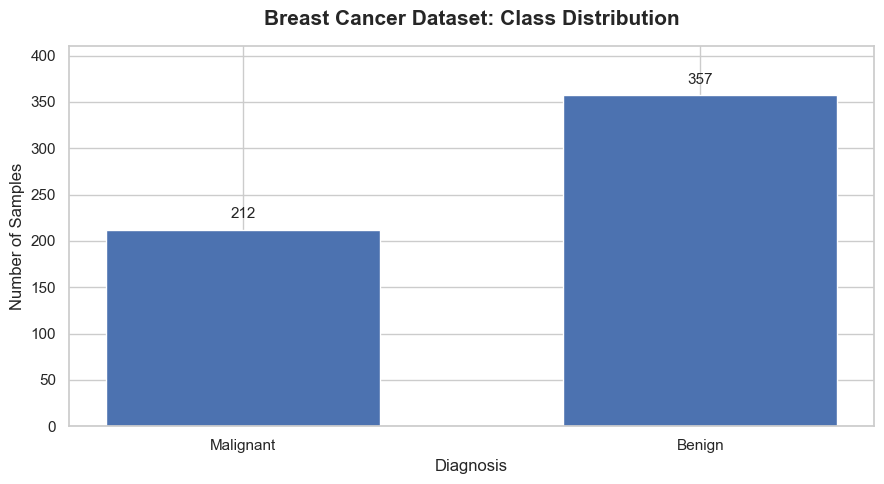


CLASS DISTRIBUTION INSIGHTS
--------------------------------------------------
Malignant   : 212 samples (37.26%)
Benign      : 357 samples (62.74%)

Interpretation: The dataset contains both malignant and benign cases. Stratified splitting preserves approximately the same class proportions across the data subsets.

[3/6] FEATURE CORRELATION ANALYSIS
--------------------------------------------------------------------------------


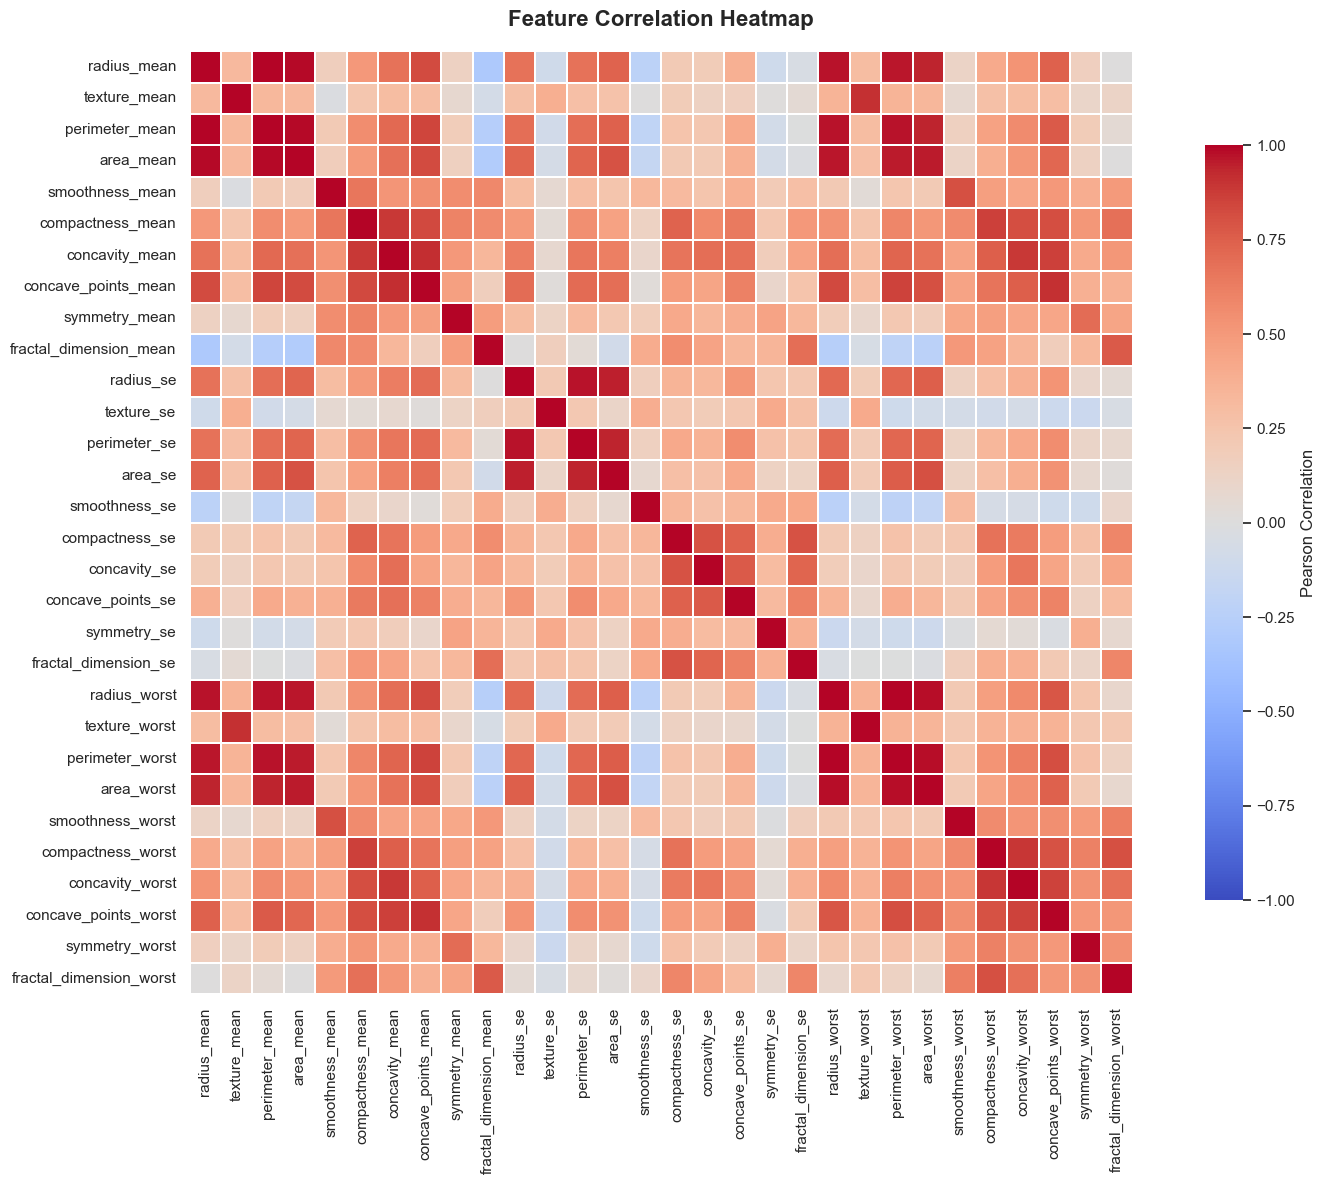


TOP 10 STRONGEST FEATURE CORRELATIONS


,,Correlation,Absolute Correlation
radius_mean,perimeter_mean,0.9979,0.9979
radius_worst,perimeter_worst,0.9937,0.9937
radius_mean,area_mean,0.9874,0.9874
perimeter_mean,area_mean,0.9865,0.9865
radius_worst,area_worst,0.9840,0.9840
perimeter_worst,area_worst,0.9776,0.9776
radius_se,perimeter_se,0.9728,0.9728
perimeter_mean,perimeter_worst,0.9704,0.9704
radius_mean,radius_worst,0.9695,0.9695
perimeter_mean,radius_worst,0.9695,0.9695



CORRELATION ANALYSIS INSIGHTS
--------------------------------------------------
1. Strong correlations indicate that some features describe related characteristics.
2. Highly correlated features may contain overlapping information.
3. Correlation alone does not establish that a feature is unnecessary.
4. All 30 features are retained for consistent model comparisons.

[4/6] STRATIFIED TRAIN/VALIDATION/TEST SPLIT
--------------------------------------------------------------------------------
Train/validation/test split validation: PASSED
Total samples          : 569
Model-training samples : 386
Validation samples     : 69
Testing samples        : 114

Model-training ratio   : 67.84%
Validation ratio       : 12.13%
Testing ratio          : 20.04%

CLASS DISTRIBUTION COMPARISON


,Full Dataset (%),Training Set (%),Validation Set (%),Testing Set (%)
Diagnosis,,,,
Malignant,37.26,37.31,37.68,36.84
Benign,62.74,62.69,62.32,63.16



Interpretation: Stratification preserves approximately the same class proportions across training, validation, and testing subsets.

[5/6] FEATURE STANDARDIZATION
--------------------------------------------------------------------------------
Feature standardization: PASSED

SCALED DATASET SHAPES
Training features   : (386, 30)
Validation features : (69, 30)
Testing features    : (114, 30)

TRAINING FEATURE MEANS — FIRST FIVE FEATURES


...


TRAINING FEATURE STANDARD DEVIATIONS — FIRST FIVE FEATURES


,Population Standard Deviation
radius_mean,1.0
texture_mean,1.0
perimeter_mean,1.0
area_mean,1.0
smoothness_mean,1.0



PREPROCESSING VALIDATION
--------------------------------------------------
Subset overlap check : PASSED
Standardization      : PASSED
Finite values check  : PASSED
Feature order check  : PASSED

Interpretation: StandardScaler learns its parameters exclusively from the model-training subset. The same parameters transform validation and test data, preventing preprocessing leakage.

[6/6] TASK COMPLETION SUMMARY


,Component,Status
0,Dataset Loading,Completed
1,Dataset Validation,Passed
2,Class Distribution Analysis,Completed
3,Feature Correlation Analysis,Completed
4,Stratified Train/Validation/Test Split,Verified
5,Feature Standardization,Verified



FINAL DATASET SUMMARY
--------------------------------------------------
Dataset samples        : 569
Input features         : 30
Model-training samples : 386
Validation samples     : 69
Testing samples        : 114
Random state           : 42
Test size              : 20%
Validation fraction    : 15% of training set
Preprocessing leakage  : Prevented

VARIABLES PREPARED FOR TASK 2
--------------------------------------------------
Training   : X_fit_scaled, y_fit
Validation : X_val_scaled, y_val
Testing    : X_test_scaled, y_test
Scaler     : scaler

TASK 1 COMPLETED SUCCESSFULLY!


In [3]:
# =============================================================================
# TASK 1: DATA LOADING, EDA & PREPROCESSING
# Project: Breast Cancer Wisconsin (Diagnostic) Classification
# Dataset Source: UCI Machine Learning Repository
# =============================================================================
#
# Configure visualizations
sns.set_theme(style="whitegrid")

print("=" * 80)
print("TASK 1: DATA LOADING, EDA & PREPROCESSING")
print("=" * 80)


# =============================================================================
# 1. DATASET LOADING AND VALIDATION
# =============================================================================

print("\n[1/6] DATASET LOADING AND VALIDATION")
print("-" * 80)

# Official UCI dataset URL
DATASET_URL = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/"
    "breast-cancer-wisconsin/wdbc.data"
)

# Generate column names in the original dataset order
column_names = (
    ["ID", "diagnosis"]
    + [
        f"{measurement}_{statistic}"
        for statistic in ["mean", "se", "worst"]
        for measurement in [
            "radius",
            "texture",
            "perimeter",
            "area",
            "smoothness",
            "compactness",
            "concavity",
            "concave_points",
            "symmetry",
            "fractal_dimension"
        ]
    ]
)

# Load dataset
df_raw = pd.read_csv(
    DATASET_URL,
    header=None,
    names=column_names
)

# Prepare features and target
X = df_raw.drop(columns=["ID", "diagnosis"]).copy()

y = df_raw["diagnosis"].map({
    "M": 0,
    "B": 1
})

# Dataset validation
assert X.shape == (569, 30), f"Unexpected feature shape: {X.shape}"
assert len(X) == len(y), "Feature and target lengths do not match."
assert X.columns.is_unique, "Duplicate feature names detected."
assert X.index.is_unique, "Duplicate feature indices detected."
assert X.index.equals(y.index), "Feature and target indices do not match."
assert X.notna().all().all(), "Missing values found in features."
assert y.notna().all(), "Missing values found in target."
assert set(y.unique()) == {0, 1}, "Unexpected target labels."
assert all(
    pd.api.types.is_numeric_dtype(dtype)
    for dtype in X.dtypes
), "All features must be numerical."
assert np.isfinite(X.to_numpy()).all(), "Infinite feature values detected."

expected_class_counts = {0: 212, 1: 357}

assert y.value_counts().to_dict() == expected_class_counts, (
    "Unexpected class counts. Verify the dataset and target encoding."
)

duplicate_count = X.duplicated().sum()

print("Dataset validation: PASSED")
print(f"Total observations : {len(X)}")
print(f"Total features     : {X.shape[1]}")
print(f"Missing values     : {X.isna().sum().sum()}")
print(f"Duplicate rows     : {duplicate_count}")

print("\nTarget Encoding")
print("0 = Malignant")
print("1 = Benign")

# Display first five observations
df = X.copy()
df["target"] = y

print("\nFIRST FIVE OBSERVATIONS")
display(df.head())

# Display descriptive statistics
print("\nFEATURE DESCRIPTIVE STATISTICS")
display(X.describe().T.round(3))


# =============================================================================
# 2. EXPLORATORY DATA ANALYSIS: CLASS DISTRIBUTION
# =============================================================================

print("\n[2/6] CLASS DISTRIBUTION ANALYSIS")
print("-" * 80)

CLASS_NAMES = {
    0: "Malignant",
    1: "Benign"
}

class_counts = (
    y.map(CLASS_NAMES)
    .value_counts()
    .reindex(["Malignant", "Benign"])
)

class_summary = pd.DataFrame({
    "Sample Count": class_counts,
    "Percentage (%)": (
        class_counts / len(y) * 100
    ).round(2)
})

display(class_summary)

# Plot class distribution
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    class_counts.index,
    class_counts.values,
    width=0.60
)

ax.bar_label(
    bars,
    fmt="%.0f",
    padding=6,
    fontsize=11
)

ax.set_title(
    "Breast Cancer Dataset: Class Distribution",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Diagnosis", fontsize=12)
ax.set_ylabel("Number of Samples", fontsize=12)
ax.set_ylim(0, class_counts.max() * 1.15)

plt.tight_layout()
plt.show()

print("\nCLASS DISTRIBUTION INSIGHTS")
print("-" * 50)

for diagnosis, row in class_summary.iterrows():
    print(
        f"{diagnosis:12s}: {int(row['Sample Count'])} samples "
        f"({row['Percentage (%)']:.2f}%)"
    )

print(
    "\nInterpretation: The dataset contains both malignant and benign "
    "cases. Stratified splitting preserves approximately the same "
    "class proportions across the data subsets."
)


# =============================================================================
# 3. EXPLORATORY DATA ANALYSIS: FEATURE CORRELATION
# =============================================================================

print("\n[3/6] FEATURE CORRELATION ANALYSIS")
print("-" * 80)

# Calculate Pearson correlation coefficients
correlation_matrix = X.corr()

# Plot correlation heatmap
fig, ax = plt.subplots(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.15,
    cbar_kws={
        "shrink": 0.8,
        "label": "Pearson Correlation"
    },
    ax=ax
)

ax.set_title(
    "Feature Correlation Heatmap",
    fontsize=16,
    fontweight="bold",
    pad=18
)

plt.tight_layout()
plt.show()

# Extract unique feature pairs
upper_triangle = np.triu(
    np.ones(correlation_matrix.shape, dtype=bool),
    k=1
)

correlation_pairs = (
    correlation_matrix
    .where(upper_triangle)
    .stack()
    .rename("Correlation")
    .to_frame()
)

correlation_pairs["Absolute Correlation"] = (
    correlation_pairs["Correlation"].abs()
)

correlation_pairs = correlation_pairs.sort_values(
    "Absolute Correlation",
    ascending=False
)

print("\nTOP 10 STRONGEST FEATURE CORRELATIONS")
display(correlation_pairs.head(10).round(4))

print("\nCORRELATION ANALYSIS INSIGHTS")
print("-" * 50)

print(
    "1. Strong correlations indicate that some features describe "
    "related characteristics."
)
print(
    "2. Highly correlated features may contain overlapping information."
)
print(
    "3. Correlation alone does not establish that a feature is unnecessary."
)
print(
    "4. All 30 features are retained for consistent model comparisons."
)


# =============================================================================
# 4. STRATIFIED TRAIN/VALIDATION/TEST SPLIT
# =============================================================================

print("\n[4/6] STRATIFIED TRAIN/VALIDATION/TEST SPLIT")
print("-" * 80)

RANDOM_STATE = 42
TEST_SIZE = 0.20
VALIDATION_SIZE = 0.15

# Split 20% of the full dataset for final testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

# Split the remaining training data into training and validation subsets
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=VALIDATION_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_train
)

# Verify split integrity
assert len(X_fit) + len(X_val) + len(X_test) == len(X)

assert set(X_fit.index).isdisjoint(X_val.index)
assert set(X_fit.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)

assert set(y_fit.unique()) == {0, 1}
assert set(y_val.unique()) == {0, 1}
assert set(y_test.unique()) == {0, 1}

print("Train/validation/test split validation: PASSED")

print(f"Total samples          : {len(X)}")
print(f"Model-training samples : {len(X_fit)}")
print(f"Validation samples     : {len(X_val)}")
print(f"Testing samples        : {len(X_test)}")

print(f"\nModel-training ratio   : {len(X_fit) / len(X):.2%}")
print(f"Validation ratio       : {len(X_val) / len(X):.2%}")
print(f"Testing ratio          : {len(X_test) / len(X):.2%}")


# Compare class proportions across subsets
def calculate_class_percentages(labels):
    return (
        labels.value_counts(normalize=True)
        .reindex([0, 1], fill_value=0)
        .mul(100)
    )


split_summary = pd.DataFrame({
    "Full Dataset (%)": calculate_class_percentages(y),
    "Training Set (%)": calculate_class_percentages(y_fit),
    "Validation Set (%)": calculate_class_percentages(y_val),
    "Testing Set (%)": calculate_class_percentages(y_test)
})

split_summary.index = split_summary.index.map(CLASS_NAMES)
split_summary.index.name = "Diagnosis"

print("\nCLASS DISTRIBUTION COMPARISON")
display(split_summary.round(2))

print(
    "\nInterpretation: Stratification preserves approximately the same "
    "class proportions across training, validation, and testing subsets."
)


# =============================================================================
# 5. FEATURE STANDARDIZATION
# =============================================================================

print("\n[5/6] FEATURE STANDARDIZATION")
print("-" * 80)

# Fit the scaler ONLY on the model-training subset
scaler = StandardScaler()

X_fit_scaled = pd.DataFrame(
    scaler.fit_transform(X_fit),
    columns=X_fit.columns,
    index=X_fit.index
)

# Transform validation and test sets using the same fitted scaler
X_val_scaled = pd.DataFrame(
    scaler.transform(X_val),
    columns=X_val.columns,
    index=X_val.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Validate standardization
assert np.allclose(
    X_fit_scaled.mean().to_numpy(),
    0,
    atol=1e-10
), "Training feature means are not approximately zero."

assert np.allclose(
    X_fit_scaled.std(ddof=0).to_numpy(),
    1,
    atol=1e-10
), "Training feature standard deviations are not approximately one."

# Check for finite transformed values
assert np.isfinite(X_fit_scaled.to_numpy()).all()
assert np.isfinite(X_val_scaled.to_numpy()).all()
assert np.isfinite(X_test_scaled.to_numpy()).all()

# Check feature order
assert list(X_fit_scaled.columns) == list(X_val_scaled.columns)
assert list(X_fit_scaled.columns) == list(X_test_scaled.columns)

print("Feature standardization: PASSED")

print("\nSCALED DATASET SHAPES")
print(f"Training features   : {X_fit_scaled.shape}")
print(f"Validation features : {X_val_scaled.shape}")
print(f"Testing features    : {X_test_scaled.shape}")

print("\nTRAINING FEATURE MEANS — FIRST FIVE FEATURES")
display(
    X_fit_scaled.mean()
    .head()
    .round(4)
    .to_frame("Mean")
)

print("\nTRAINING FEATURE STANDARD DEVIATIONS — FIRST FIVE FEATURES")
display(
    X_fit_scaled.std(ddof=0)
    .head()
    .round(4)
    .to_frame("Population Standard Deviation")
)

print("\nPREPROCESSING VALIDATION")
print("-" * 50)
print("Subset overlap check : PASSED")
print("Standardization      : PASSED")
print("Finite values check  : PASSED")
print("Feature order check  : PASSED")

print(
    "\nInterpretation: StandardScaler learns its parameters exclusively "
    "from the model-training subset. The same parameters transform "
    "validation and test data, preventing preprocessing leakage."
)


# =============================================================================
# 6. FINAL TASK SUMMARY
# =============================================================================

print("\n[6/6] TASK COMPLETION SUMMARY")
print("=" * 80)

task_summary = pd.DataFrame({
    "Component": [
        "Dataset Loading",
        "Dataset Validation",
        "Class Distribution Analysis",
        "Feature Correlation Analysis",
        "Stratified Train/Validation/Test Split",
        "Feature Standardization"
    ],
    "Status": [
        "Completed",
        "Passed",
        "Completed",
        "Completed",
        "Verified",
        "Verified"
    ]
})

display(task_summary)

print("\nFINAL DATASET SUMMARY")
print("-" * 50)
print(f"Dataset samples        : {len(X)}")
print(f"Input features         : {X.shape[1]}")
print(f"Model-training samples : {len(X_fit_scaled)}")
print(f"Validation samples     : {len(X_val_scaled)}")
print(f"Testing samples        : {len(X_test_scaled)}")
print(f"Random state           : {RANDOM_STATE}")
print(f"Test size              : {TEST_SIZE:.0%}")
print(f"Validation fraction    : {VALIDATION_SIZE:.0%} of training set")
print("Preprocessing leakage  : Prevented")

print("\nVARIABLES PREPARED FOR TASK 2")
print("-" * 50)
print("Training   : X_fit_scaled, y_fit")
print("Validation : X_val_scaled, y_val")
print("Testing    : X_test_scaled, y_test")
print("Scaler     : scaler")

print("\nTASK 1 COMPLETED SUCCESSFULLY!")
print("=" * 80)

TASK 2: SINGLE-LAYER PERCEPTRON BASELINE

Dataset Verification
----------------------------------------
Training samples   : 386
Validation samples : 69
Test samples       : 114
Input features     : 30

Class Mapping
0 = Malignant
1 = Benign

SLP Training Configuration
----------------------------------------
Combined training pool: 455 samples
Validation split      : 10%
Epochs                : 50
Batch size            : 32

Model Architecture
----------------------------------------


Model: "SLP_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ output_layer (Dense)                 │ (None, 1)                   │              31 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 31 (124.00 B)

 Trainable params: 31 (124.00 B)

 Non-trainable params: 0 (0.00 B)


PASS: SLP contains exactly 31 parameters.
Epoch 1/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.4719 - loss: 0.8219 - val_accuracy: 0.6304 - val_loss: 0.7205
Epoch 2/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5795 - loss: 0.7419 - val_accuracy: 0.6739 - val_loss: 0.6668
Epoch 3/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6601 - loss: 0.6734 - val_accuracy: 0.7174 - val_loss: 0.6206
Epoch 4/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.7042 - loss: 0.6157 - val_accuracy: 0.7391 - val_loss: 0.5811
Epoch 5/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.7482 - loss: 0.5672 - val_accuracy: 0.7391 - val_loss: 0.5471
Epoch 6/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.7775 - loss: 0.5261 - val_accuracy: 0.7826 - val_loss: 0.5176
Epoch 7/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8093 - loss: 0.4908 - val_accuracy: 0.8043 - val_loss: 0.4917
Epoch 8/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.836

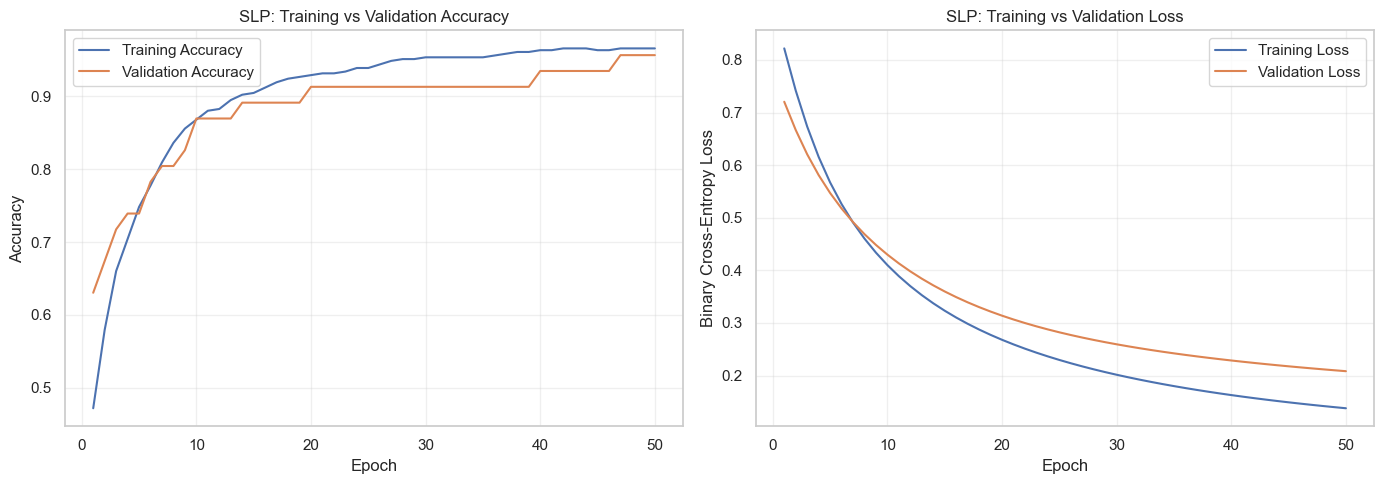


Validation Performance
----------------------------------------
Best validation-loss epoch : 50
Best validation loss       : 0.2082
Best validation-accuracy epoch : 47
Best validation accuracy      : 0.9565

Final Test Performance — SLP Baseline
Test Loss               : 0.1725
Test Accuracy           : 0.9561
Precision (Benign)      : 0.9589
Recall (Benign)         : 0.9722
Recall (Malignant)      : 0.9286
F1-Score (Benign)       : 0.9655

Classification Report
              precision    recall  f1-score   support

   Malignant     0.9512    0.9286    0.9398        42
      Benign     0.9589    0.9722    0.9655        72

    accuracy                         0.9561       114
   macro avg     0.9551    0.9504    0.9526       114
weighted avg     0.9561    0.9561    0.9560       114



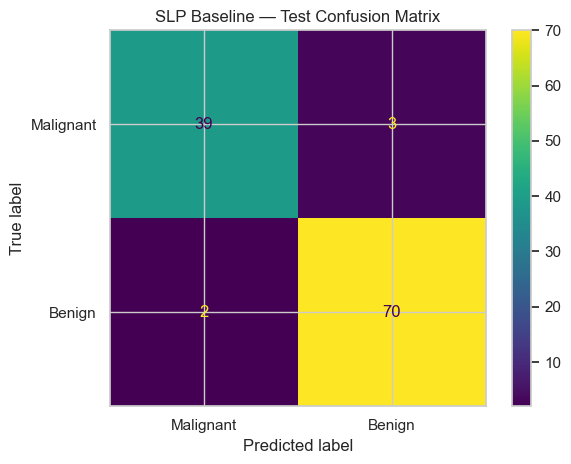


Baseline Results Table


,Model,Architecture,Training Accuracy,Validation Accuracy,Test Loss,Test Accuracy,Test Precision,Test Recall,Test F1-Score,Malignant Recall
0,SLP Baseline,30 inputs -> 1 sigmoid output,0.9658,0.9565,0.1725,0.9561,0.9589,0.9722,0.9655,0.9286



Task 2 completed successfully!
Actual SLP results are saved for the Task 7 comparison.


In [5]:
# ============================================================
# TASK 2: SINGLE-LAYER PERCEPTRON (SLP) BASELINE MODEL
# ============================================================

# -------------------- 1. REPRODUCIBILITY --------------------

SEED = 42

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("=" * 65)
print("TASK 2: SINGLE-LAYER PERCEPTRON BASELINE")
print("=" * 65)


# -------------------- 2. VALIDATE INPUT DATA ----------------

required_variables = [
    "X_fit_scaled",
    "y_fit",
    "X_val_scaled",
    "y_val",
    "X_test_scaled",
    "y_test"
]

missing_variables = [
    variable for variable in required_variables
    if variable not in globals()
]

if missing_variables:
    raise NameError(
        f"Missing Task 1 variables: {missing_variables}. "
        "Run Task 1 successfully before running Task 2."
    )

y_fit_array = np.asarray(y_fit).astype(np.int32).ravel()
y_val_array = np.asarray(y_val).astype(np.int32).ravel()
y_test_array = np.asarray(y_test).astype(np.int32).ravel()

assert X_fit_scaled.shape[0] == len(y_fit_array)
assert X_val_scaled.shape[0] == len(y_val_array)
assert X_test_scaled.shape[0] == len(y_test_array)

assert X_fit_scaled.shape[1] == X_val_scaled.shape[1]
assert X_fit_scaled.shape[1] == X_test_scaled.shape[1]

assert X_fit_scaled.shape[1] == 30

assert set(np.unique(y_fit_array)).issubset({0, 1})
assert set(np.unique(y_val_array)).issubset({0, 1})
assert set(np.unique(y_test_array)).issubset({0, 1})

print("\nDataset Verification")
print("-" * 40)
print(f"Training samples   : {len(y_fit_array)}")
print(f"Validation samples : {len(y_val_array)}")
print(f"Test samples       : {len(y_test_array)}")
print(f"Input features     : {X_fit_scaled.shape[1]}")

print("\nClass Mapping")
print("0 = Malignant")
print("1 = Benign")


# -------------------- 3. PREPARE VALIDATION SPLIT -----------

# The assignment specifies validation_split=0.1.
# Combine the original training and validation subsets,
# then let Keras reserve 10% for validation.
# The test set remains completely separate.

X_slp_train = np.concatenate(
    [X_fit_scaled, X_val_scaled],
    axis=0
)

y_slp_train = np.concatenate(
    [y_fit_array, y_val_array],
    axis=0
)

print("\nSLP Training Configuration")
print("-" * 40)
print(f"Combined training pool: {len(y_slp_train)} samples")
print("Validation split      : 10%")
print("Epochs                : 50")
print("Batch size            : 32")


# -------------------- 4. BUILD AND COMPILE SLP --------------

slp_model = keras.Sequential(
    [
        keras.Input(shape=(X_fit_scaled.shape[1],)),
        layers.Dense(
            units=1,
            activation="sigmoid",
            name="output_layer"
        )
    ],
    name="SLP_Baseline"
)

slp_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("\nModel Architecture")
print("-" * 40)

slp_model.summary()

assert slp_model.count_params() == 31

print("\nPASS: SLP contains exactly 31 parameters.")


# -------------------- 5. TRAIN THE MODEL --------------------

EPOCHS = 50
BATCH_SIZE = 32

history_slp = slp_model.fit(
    X_slp_train,
    y_slp_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.1,
    shuffle=True,
    verbose=1
)


# -------------------- 6. VISUALIZE TRAINING -----------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epoch_numbers = range(
    1,
    len(history_slp.history["loss"]) + 1
)

# Accuracy curves
axes[0].plot(
    epoch_numbers,
    history_slp.history["accuracy"],
    label="Training Accuracy"
)

axes[0].plot(
    epoch_numbers,
    history_slp.history["val_accuracy"],
    label="Validation Accuracy"
)

axes[0].set_title("SLP: Training vs Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Loss curves
axes[1].plot(
    epoch_numbers,
    history_slp.history["loss"],
    label="Training Loss"
)

axes[1].plot(
    epoch_numbers,
    history_slp.history["val_loss"],
    label="Validation Loss"
)

axes[1].set_title("SLP: Training vs Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Binary Cross-Entropy Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# -------------------- 7. VALIDATION PERFORMANCE -------------

best_val_loss_epoch = (
    int(np.argmin(history_slp.history["val_loss"])) + 1
)

best_val_accuracy_epoch = (
    int(np.argmax(history_slp.history["val_accuracy"])) + 1
)

print("\nValidation Performance")
print("-" * 40)

print(
    f"Best validation-loss epoch : {best_val_loss_epoch}"
)

print(
    f"Best validation loss       : "
    f"{min(history_slp.history['val_loss']):.4f}"
)

print(
    f"Best validation-accuracy epoch : "
    f"{best_val_accuracy_epoch}"
)

print(
    f"Best validation accuracy      : "
    f"{max(history_slp.history['val_accuracy']):.4f}"
)

# -------------------- 8. TEST EVALUATION --------------------

test_loss, test_accuracy = slp_model.evaluate(
    X_test_scaled,
    y_test_array,
    verbose=0
)

test_probabilities = slp_model.predict(
    X_test_scaled,
    verbose=0
).ravel()

y_test_pred = (
    test_probabilities >= 0.5
).astype(np.int32)

# Positive class is Benign (class 1).
test_precision = precision_score(
    y_test_array,
    y_test_pred,
    pos_label=1,
    zero_division=0
)

test_recall_benign = recall_score(
    y_test_array,
    y_test_pred,
    pos_label=1,
    zero_division=0
)

test_recall_malignant = recall_score(
    y_test_array,
    y_test_pred,
    pos_label=0,
    zero_division=0
)

test_f1 = f1_score(
    y_test_array,
    y_test_pred,
    pos_label=1,
    zero_division=0
)

print("\nFinal Test Performance — SLP Baseline")
print("=" * 50)
print(f"Test Loss               : {test_loss:.4f}")
print(f"Test Accuracy           : {test_accuracy:.4f}")
print(f"Precision (Benign)      : {test_precision:.4f}")
print(f"Recall (Benign)         : {test_recall_benign:.4f}")
print(f"Recall (Malignant)      : {test_recall_malignant:.4f}")
print(f"F1-Score (Benign)       : {test_f1:.4f}")


# -------------------- 9. CLASSIFICATION REPORT --------------

print("\nClassification Report")
print("=" * 50)

print(
    classification_report(
        y_test_array,
        y_test_pred,
        labels=[0, 1],
        target_names=["Malignant", "Benign"],
        digits=4,
        zero_division=0
    )
)


# -------------------- 10. CONFUSION MATRIX -----------------

cm = confusion_matrix(
    y_test_array,
    y_test_pred,
    labels=[0, 1]
)

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Malignant", "Benign"]
)

cm_display.plot(values_format="d")
plt.title("SLP Baseline — Test Confusion Matrix")
plt.tight_layout()
plt.show()


# -------------------- 11. SAVE RESULTS FOR TASK 7 -----------

slp_report = classification_report(
    y_test_array,
    y_test_pred,
    labels=[0, 1],
    target_names=["Malignant", "Benign"],
    output_dict=True,
    zero_division=0
)

slp_results = {
    "Model": "SLP Baseline",
    "Architecture": "30 inputs -> 1 sigmoid output",
    "Training Accuracy": float(
        history_slp.history["accuracy"][-1]
    ),
    "Validation Accuracy": float(
        history_slp.history["val_accuracy"][-1]
    ),
    "Test Loss": float(test_loss),
    "Test Accuracy": float(test_accuracy),
    "Test Precision": float(slp_report["Benign"]["precision"]),
    "Test Recall": float(slp_report["Benign"]["recall"]),
    "Test F1-Score": float(slp_report["Benign"]["f1-score"]),
    "Malignant Recall": float(slp_report["Malignant"]["recall"])
}

slp_results_df = pd.DataFrame([slp_results])

print("\nBaseline Results Table")
print("=" * 65)

display(slp_results_df.round(4))

print("\nTask 2 completed successfully!")
print("Actual SLP results are saved for the Task 7 comparison.")

TASK 3: MLP ACTIVATION FUNCTION COMPARISON

Dataset Information
---------------------------------------------
Training samples   : 386
Validation samples : 69
Test samples       : 114
Input features     : 30

Training MLP with RELU activation



Model: "MLP_relu"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ hidden_layer_1 (Dense)               │ (None, 64)                  │           1,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ hidden_layer_2 (Dense)               │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output_layer (Dense)                 │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,097 (16.00 KB)

 Trainable params: 4,097 (16.00 KB)

...

 Total params: 4,097 (16.00 KB)

 Trainable params: 4,097 (16.00 KB)

 Non-trainable params: 0 (0.00 B)


Best validation accuracy : 0.9710
Best validation loss     : 0.0903
Best epoch               : 14
Training time            : 34.54 seconds

MLP ACTIVATION FUNCTION COMPARISON


,Activation,Best Epoch (Val Accuracy),Best Validation Accuracy,Best Validation Loss,Final Training Accuracy,Final Validation Accuracy,Training Time (seconds)
0,tanh,39,0.9855,0.0724,1.0000,0.9710,35.1844
1,relu,10,0.9710,0.1009,1.0000,0.9565,34.4704
2,sigmoid,14,0.9710,0.0903,0.9922,0.9710,34.5380


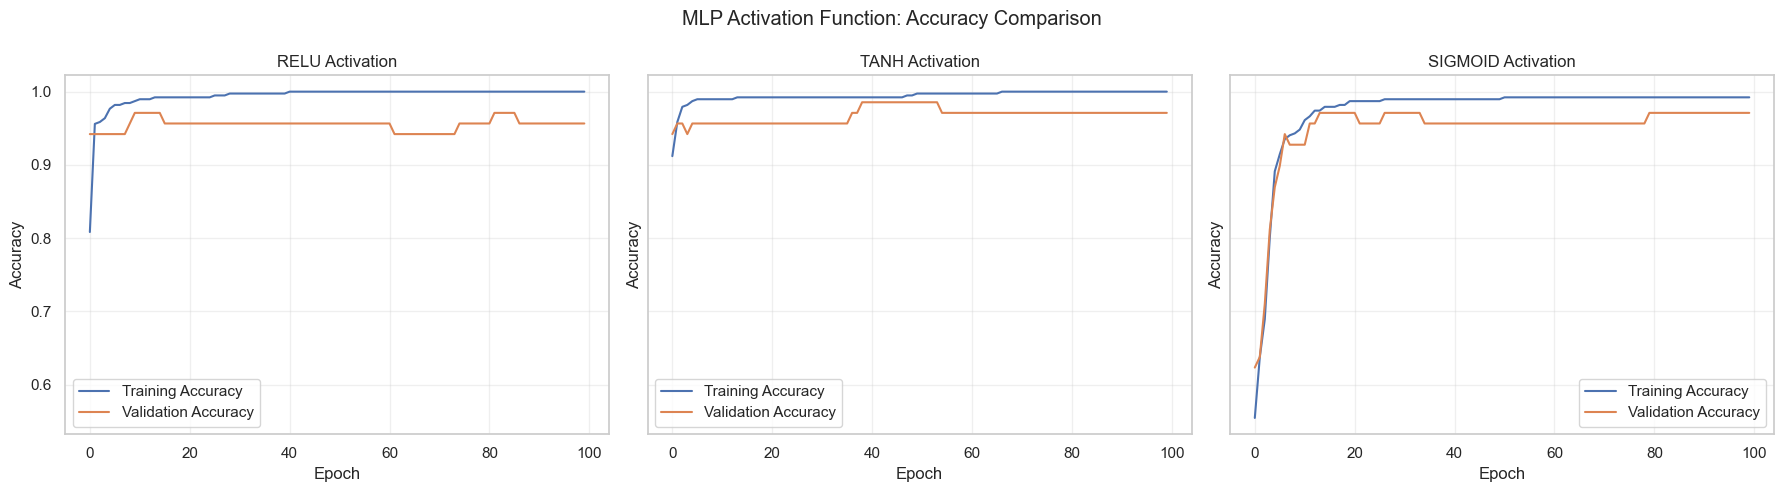

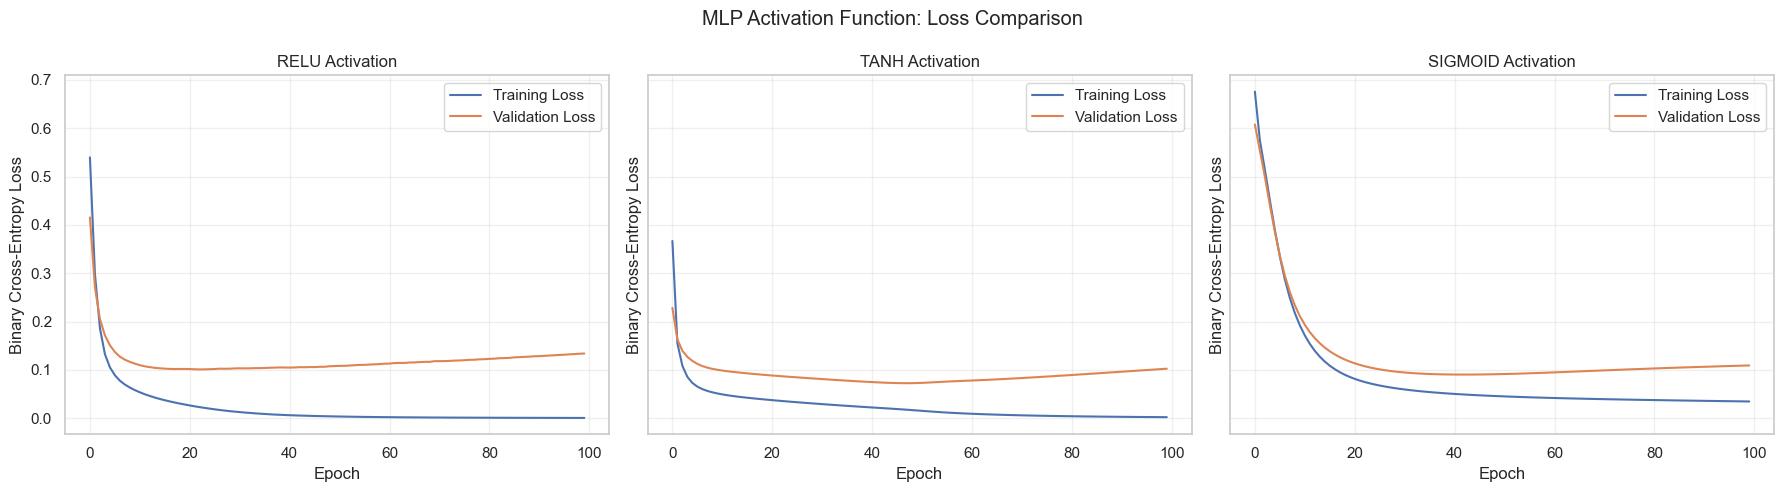


Best MLP Based on Validation Accuracy
--------------------------------------------------
Activation function : TANH
Best validation accuracy : 0.9855

Selected MLP — Test Performance
Selected activation       : TANH
Test Loss                 : 0.0894
Test Accuracy             : 0.9737
Precision (Benign)        : 0.9859
Recall (Benign)            : 0.9722
Recall (Malignant)        : 0.9762
F1-Score (Benign)         : 0.9790

Classification Report — Selected MLP
              precision    recall  f1-score   support

   Malignant     0.9535    0.9762    0.9647        42
      Benign     0.9859    0.9722    0.9790        72

    accuracy                         0.9737       114
   macro avg     0.9697    0.9742    0.9719       114
weighted avg     0.9740    0.9737    0.9737       114



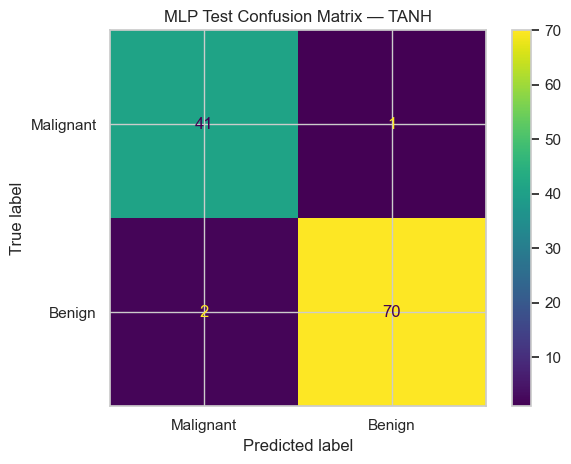


SLP vs Selected MLP


,Model,Test Accuracy,Test Loss
0,SLP Baseline,0.9649,0.1216
1,MLP (tanh),0.9737,0.0894



TASK 3 COMPLETED SUCCESSFULLY
Activation functions evaluated: relu, tanh, sigmoid
Best activation on validation set: TANH
Results table variable: mlp_results
Trained models variable: mlp_models
Training histories variable: mlp_histories


In [4]:
# ============================================================
# TASK 3: MLP ACTIVATION FUNCTION COMPARISON
# Dataset: UCI Breast Cancer Wisconsin Diagnostic Dataset
# Activations: ReLU, tanh, sigmoid
# ============================================================


# -------------------- 1. CONFIGURATION -----------------------

SEED = 42
EPOCHS = 100
BATCH_SIZE = 32
LEARNING_RATE = 0.001

ACTIVATIONS = ["relu", "tanh", "sigmoid"]

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("=" * 70)
print("TASK 3: MLP ACTIVATION FUNCTION COMPARISON")
print("=" * 70)


# -------------------- 2. VERIFY DATA -------------------------

required_variables = [
    "X_fit_scaled",
    "y_fit",
    "X_val_scaled",
    "y_val",
    "X_test_scaled",
    "y_test"
]

missing_variables = [
    variable for variable in required_variables
    if variable not in globals()
]

if missing_variables:
    raise NameError(
        f"Missing variables: {missing_variables}. "
        "Run Task 1 successfully before Task 3."
    )

y_fit_array = np.asarray(y_fit).astype(np.int32).ravel()
y_val_array = np.asarray(y_val).astype(np.int32).ravel()
y_test_array = np.asarray(y_test).astype(np.int32).ravel()

assert X_fit_scaled.shape[1] == X_val_scaled.shape[1]
assert X_fit_scaled.shape[1] == X_test_scaled.shape[1]

print("\nDataset Information")
print("-" * 45)
print(f"Training samples   : {X_fit_scaled.shape[0]}")
print(f"Validation samples : {X_val_scaled.shape[0]}")
print(f"Test samples       : {X_test_scaled.shape[0]}")
print(f"Input features     : {X_fit_scaled.shape[1]}")


# -------------------- 3. DEFINE MODEL BUILDER ----------------

def build_mlp(activation, input_features):
    """
    Create an MLP with two hidden layers and one sigmoid output.

    Architecture:
        Input -> Dense(64) -> Dense(32) -> Dense(1)
    """

    model = keras.Sequential(
        [
            keras.Input(shape=(input_features,)),

            layers.Dense(
                units=64,
                activation=activation,
                name="hidden_layer_1"
            ),

            layers.Dense(
                units=32,
                activation=activation,
                name="hidden_layer_2"
            ),

            layers.Dense(
                units=1,
                activation="sigmoid",
                name="output_layer"
            )
        ],
        name=f"MLP_{activation}"
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


# -------------------- 4. TRAIN MODELS ------------------------

mlp_models = {}
mlp_histories = {}
mlp_results_list = []

for activation in ACTIVATIONS:

    print("\n" + "=" * 70)
    print(f"Training MLP with {activation.upper()} activation")
    print("=" * 70)

    # Reset seed before each model for reproducibility.
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    model = build_mlp(
        activation=activation,
        input_features=X_fit_scaled.shape[1]
    )

    model.summary()

    start_time = __import__("time").perf_counter()

    history = model.fit(
        X_fit_scaled,
        y_fit_array,
        validation_data=(X_val_scaled, y_val_array),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    training_time = __import__("time").perf_counter() - start_time

    # Store the model and training history.
    mlp_models[activation] = model
    mlp_histories[activation] = history

    # Find the epoch with the highest validation accuracy.
    best_epoch = int(
        np.argmax(history.history["val_accuracy"]) + 1
    )

    best_val_accuracy = float(
        np.max(history.history["val_accuracy"])
    )

    best_val_loss = float(
        np.min(history.history["val_loss"])
    )

    # Record the final epoch metrics as well.
    final_train_accuracy = float(
        history.history["accuracy"][-1]
    )

    final_val_accuracy = float(
        history.history["val_accuracy"][-1]
    )

    mlp_results_list.append(
        {
            "Activation": activation,
            "Best Epoch (Val Accuracy)": best_epoch,
            "Best Validation Accuracy": best_val_accuracy,
            "Best Validation Loss": best_val_loss,
            "Final Training Accuracy": final_train_accuracy,
            "Final Validation Accuracy": final_val_accuracy,
            "Training Time (seconds)": training_time
        }
    )

    print(f"\nBest validation accuracy : {best_val_accuracy:.4f}")
    print(f"Best validation loss     : {best_val_loss:.4f}")
    print(f"Best epoch               : {best_epoch}")
    print(f"Training time            : {training_time:.2f} seconds")


# -------------------- 5. COMPARE VALIDATION RESULTS ----------

mlp_results = pd.DataFrame(mlp_results_list)

mlp_results = mlp_results.sort_values(
    by="Best Validation Accuracy",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 90)
print("MLP ACTIVATION FUNCTION COMPARISON")
print("=" * 90)

display(mlp_results.round(4))


# -------------------- 6. PLOT ACCURACY CURVES ----------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5),
    sharey=True
)

for ax, activation in zip(axes, ACTIVATIONS):

    history = mlp_histories[activation]

    ax.plot(
        history.history["accuracy"],
        label="Training Accuracy"
    )

    ax.plot(
        history.history["val_accuracy"],
        label="Validation Accuracy"
    )

    ax.set_title(f"{activation.upper()} Activation")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle("MLP Activation Function: Accuracy Comparison")
plt.tight_layout()
plt.show()


# -------------------- 7. PLOT LOSS CURVES --------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5),
    sharey=True
)

for ax, activation in zip(axes, ACTIVATIONS):

    history = mlp_histories[activation]

    ax.plot(
        history.history["loss"],
        label="Training Loss"
    )

    ax.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    ax.set_title(f"{activation.upper()} Activation")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Binary Cross-Entropy Loss")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle("MLP Activation Function: Loss Comparison")
plt.tight_layout()
plt.show()


# -------------------- 8. SELECT BEST ACTIVATION --------------

# Select the model with the highest validation accuracy.
best_activation = mlp_results.loc[0, "Activation"]
best_mlp_model = mlp_models[best_activation]

print("\nBest MLP Based on Validation Accuracy")
print("-" * 50)
print(f"Activation function : {best_activation.upper()}")
print(
    "Best validation accuracy : "
    f"{mlp_results.loc[0, 'Best Validation Accuracy']:.4f}"
)


# -------------------- 9. TEST EVALUATION ---------------------

# Evaluate the selected model on the held-out test set.
# This is an experiment-level test evaluation; avoid using
# these results to repeatedly tune the model.

test_loss, test_accuracy = best_mlp_model.evaluate(
    X_test_scaled,
    y_test_array,
    verbose=0
)

test_probabilities = best_mlp_model.predict(
    X_test_scaled,
    verbose=0
).ravel()

y_test_pred_mlp = (
    test_probabilities >= 0.5
).astype(np.int32)

test_precision_benign = precision_score(
    y_test_array,
    y_test_pred_mlp,
    pos_label=1,
    zero_division=0
)

test_recall_benign = recall_score(
    y_test_array,
    y_test_pred_mlp,
    pos_label=1,
    zero_division=0
)

test_recall_malignant = recall_score(
    y_test_array,
    y_test_pred_mlp,
    pos_label=0,
    zero_division=0
)

test_f1_benign = f1_score(
    y_test_array,
    y_test_pred_mlp,
    pos_label=1,
    zero_division=0
)

print("\nSelected MLP — Test Performance")
print("=" * 55)
print(f"Selected activation       : {best_activation.upper()}")
print(f"Test Loss                 : {test_loss:.4f}")
print(f"Test Accuracy             : {test_accuracy:.4f}")
print(f"Precision (Benign)        : {test_precision_benign:.4f}")
print(f"Recall (Benign)            : {test_recall_benign:.4f}")
print(f"Recall (Malignant)        : {test_recall_malignant:.4f}")
print(f"F1-Score (Benign)         : {test_f1_benign:.4f}")


# -------------------- 10. CLASSIFICATION REPORT --------------

print("\nClassification Report — Selected MLP")
print("=" * 55)

print(
    classification_report(
        y_test_array,
        y_test_pred_mlp,
        labels=[0, 1],
        target_names=["Malignant", "Benign"],
        digits=4,
        zero_division=0
    )
)


# -------------------- 11. CONFUSION MATRIX ------------------

cm_mlp = confusion_matrix(
    y_test_array,
    y_test_pred_mlp,
    labels=[0, 1]
)

cm_display_mlp = ConfusionMatrixDisplay(
    confusion_matrix=cm_mlp,
    display_labels=["Malignant", "Benign"]
)

cm_display_mlp.plot(values_format="d")
plt.title(f"MLP Test Confusion Matrix — {best_activation.upper()}")
plt.tight_layout()
plt.show()


# -------------------- 12. COMPARE WITH SLP BASELINE ---------

# Task 2's slp_results table is expected to exist.
if "slp_results" in globals():

    print("\nSLP vs Selected MLP")
    print("=" * 70)

    model_comparison = pd.DataFrame(
        [
            {
                "Model": "SLP Baseline",
                "Test Accuracy": float(
                    slp_results.iloc[0]["Test Accuracy"]
                ),
                "Test Loss": float(
                    slp_results.iloc[0]["Test Loss"]
                )
            },
            {
                "Model": f"MLP ({best_activation})",
                "Test Accuracy": float(test_accuracy),
                "Test Loss": float(test_loss)
            }
        ]
    )

    display(model_comparison.round(4))

else:
    print(
        "\nThe SLP results table was not found. "
        "The MLP results are available in mlp_results."
    )


# -------------------- 13. TASK SUMMARY -----------------------

print("\n" + "=" * 70)
print("TASK 3 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("Activation functions evaluated:", ", ".join(ACTIVATIONS))
print("Best activation on validation set:", best_activation.upper())
print("Results table variable: mlp_results")
print("Trained models variable: mlp_models")
print("Training histories variable: mlp_histories")

TASK 4: EARLYSTOPPING COMPARISON

Dataset Information
---------------------------------------------
Training samples   : 386
Validation samples : 69
Test samples       : 114
Input features     : 30

EXPERIMENT A: WITHOUT EARLYSTOPPING



Model: "MLP_EarlyStopping_Experiment"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ hidden_layer_1 (Dense)               │ (None, 128)                 │           3,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ hidden_layer_2 (Dense)               │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output_layer (Dense)                 │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 12,289 (48.00 KB)

 Trainable params: 12,289 (48.00 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ hidden_layer_1 (Dense)               │ (None, 128)                 │           3,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ hidden_layer_2 (Dense)               │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output_layer (Dense)                 │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 12,289 (48.00 KB)

 Trainable params: 12,289 (48.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 53: early stopping
Restoring model weights from the end of the best epoch: 38.

Epochs trained                : 53
Best validation-loss epoch    : 38
Best validation loss          : 0.0691
Best validation-accuracy epoch: 2
Best validation accuracy      : 0.9710
Final recorded validation accuracy: 0.9710
Training time                 : 18.11 seconds
EarlyStopping patience        : 15
Best validation-loss weights restored: True


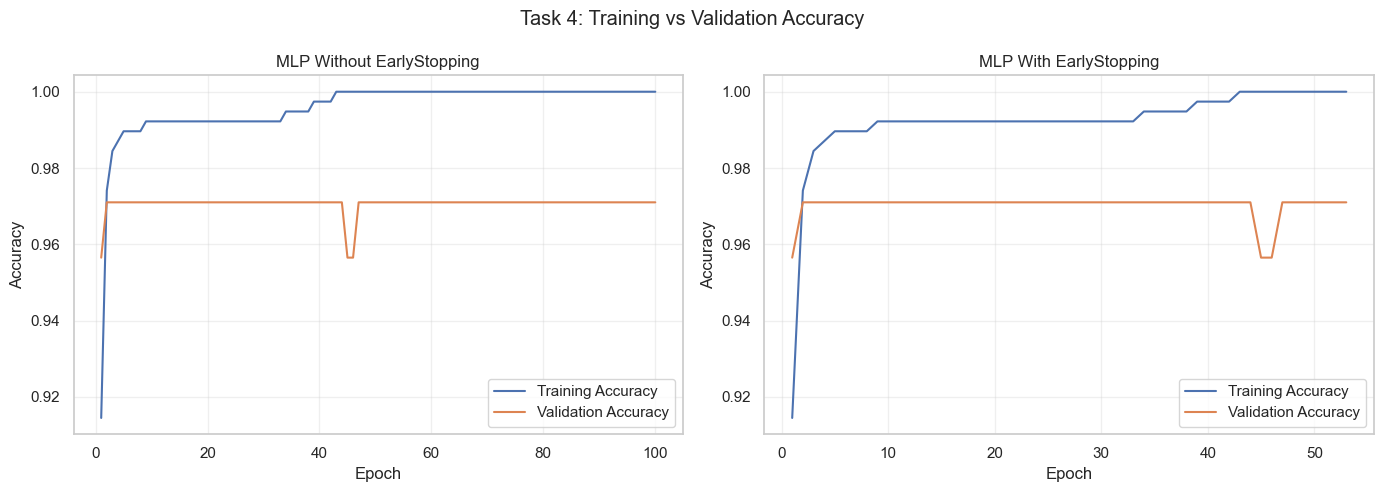

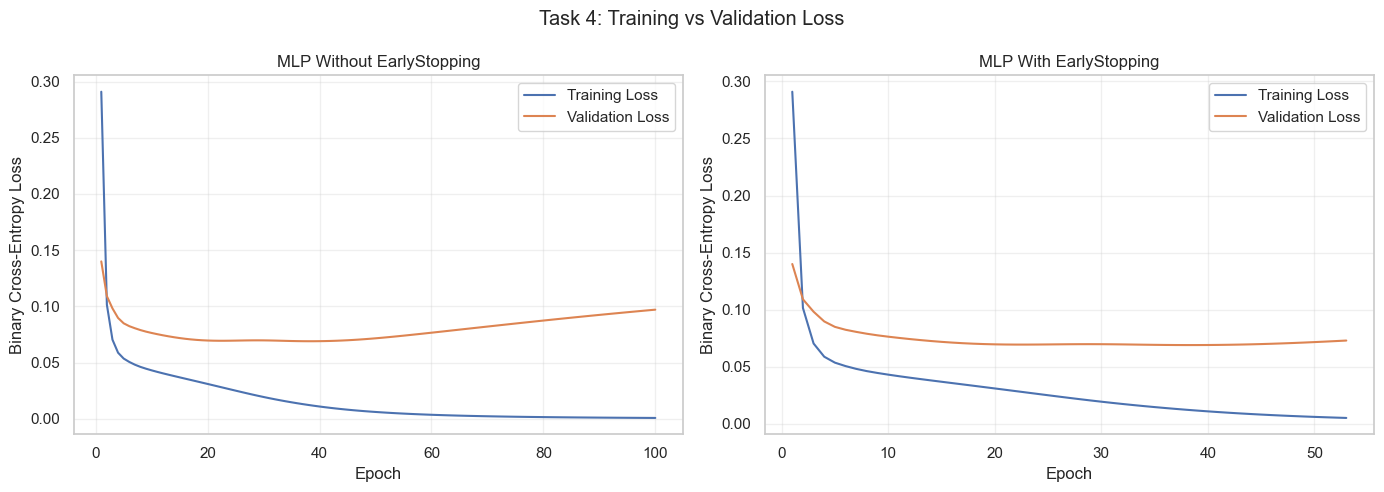


EARLYSTOPPING VALIDATION COMPARISON


,Model,Architecture,Epochs Trained,Best Loss Epoch,Best Validation Loss,Best Validation Accuracy,Best Accuracy Epoch,Final Validation Accuracy,Training Time (seconds)
0,MLP Without EarlyStopping,30 -> 128 -> 64 -> 1,100,38,0.0691,0.971,2,0.971,33.7445
1,MLP With EarlyStopping,30 -> 128 -> 64 -> 1,53,38,0.0691,0.971,2,0.971,18.1052



FINAL TEST PERFORMANCE COMPARISON


,Model,Test Loss,Test Accuracy,Precision (Benign),Recall (Malignant),Recall (Benign),F1-Score (Benign)
0,MLP Without EarlyStopping,0.1135,0.9737,0.9859,0.9762,0.9722,0.979
1,MLP With EarlyStopping,0.0837,0.9737,0.9859,0.9762,0.9722,0.979



Training Efficiency
---------------------------------------------
Epoch reduction : 47.00%
Time reduction  : 46.35%
EarlyStopping reduced measured training time in this run.

TASK 4 COMPLETED SUCCESSFULLY
Baseline model variable      : mlp_without_es
EarlyStopping model variable : mlp_with_es
Validation comparison table  : early_stopping_results
Test comparison table        : early_stopping_test_results
EarlyStopping patience       : 15
Best loss epoch with ES     : 38
Best validation loss with ES: 0.0691


In [11]:

# ============================================================
# TASK 4: EARLYSTOPPING COMPARISON
# Dataset: UCI Breast Cancer Wisconsin Diagnostic Dataset
# ============================================================

# -------------------- 1. CONFIGURATION -----------------------

SEED = 42
EPOCHS = 100
BATCH_SIZE = 32
LEARNING_RATE = 0.001
PATIENCE = 15

print("=" * 70)
print("TASK 4: EARLYSTOPPING COMPARISON")
print("=" * 70)

# -------------------- 2. VERIFY DATA -------------------------

required_variables = [
    "X_fit_scaled",
    "y_fit",
    "X_val_scaled",
    "y_val",
    "X_test_scaled",
    "y_test"
]

missing_variables = [
    variable for variable in required_variables
    if variable not in globals()
]

if missing_variables:
    raise NameError(
        f"Missing variables: {missing_variables}. "
        "Run Task 1 successfully before Task 4."
    )

y_fit_array = np.asarray(y_fit).astype(np.int32).ravel()
y_val_array = np.asarray(y_val).astype(np.int32).ravel()
y_test_array = np.asarray(y_test).astype(np.int32).ravel()

print("\nDataset Information")
print("-" * 45)
print(f"Training samples   : {X_fit_scaled.shape[0]}")
print(f"Validation samples : {X_val_scaled.shape[0]}")
print(f"Test samples       : {X_test_scaled.shape[0]}")
print(f"Input features     : {X_fit_scaled.shape[1]}")

assert X_fit_scaled.shape[1] == X_val_scaled.shape[1]
assert X_fit_scaled.shape[1] == X_test_scaled.shape[1]
assert len(X_fit_scaled) == len(y_fit_array)
assert len(X_val_scaled) == len(y_val_array)
assert len(X_test_scaled) == len(y_test_array)

# -------------------- 3. DEFINE MODEL BUILDER ----------------

def build_earlystopping_mlp(input_features):
    """
    Fixed architecture for a fair EarlyStopping comparison.

    Architecture:
    Input -> Dense(128, tanh) -> Dense(64, tanh)
          -> Dense(1, sigmoid)
    """

    model = keras.Sequential(
        [
            keras.Input(shape=(input_features,)),

            layers.Dense(
                128,
                activation="tanh",
                name="hidden_layer_1"
            ),

            layers.Dense(
                64,
                activation="tanh",
                name="hidden_layer_2"
            ),

            layers.Dense(
                1,
                activation="sigmoid",
                name="output_layer"
            )
        ],
        name="MLP_EarlyStopping_Experiment"
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


# -------------------- 4. TRAIN WITHOUT EARLYSTOPPING ----------

print("\n" + "=" * 70)
print("EXPERIMENT A: WITHOUT EARLYSTOPPING")
print("=" * 70)

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

mlp_without_es = build_earlystopping_mlp(
    input_features=X_fit_scaled.shape[1]
)

mlp_without_es.summary()

start_time = time.perf_counter()

history_without_es = mlp_without_es.fit(
    X_fit_scaled,
    y_fit_array,
    validation_data=(X_val_scaled, y_val_array),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    verbose=0
)

time_without_es = time.perf_counter() - start_time

best_epoch_without_es = (
    int(np.argmin(history_without_es.history["val_loss"])) + 1
)

best_val_loss_without_es = float(
    np.min(history_without_es.history["val_loss"])
)

best_val_accuracy_epoch_without_es = (
    int(np.argmax(history_without_es.history["val_accuracy"])) + 1
)

best_val_accuracy_without_es = float(
    np.max(history_without_es.history["val_accuracy"])
)

final_val_accuracy_without_es = float(
    history_without_es.history["val_accuracy"][-1]
)

print(f"\nEpochs trained                : {len(history_without_es.history['loss'])}")
print(f"Best validation-loss epoch    : {best_epoch_without_es}")
print(f"Best validation loss          : {best_val_loss_without_es:.4f}")
print(
    f"Best validation-accuracy epoch: "
    f"{best_val_accuracy_epoch_without_es}"
)
print(f"Best validation accuracy      : {best_val_accuracy_without_es:.4f}")
print(f"Final validation accuracy     : {final_val_accuracy_without_es:.4f}")
print(f"Training time                 : {time_without_es:.2f} seconds")


# -------------------- 5. TRAIN WITH EARLYSTOPPING --------------

print("\n" + "=" * 70)
print("EXPERIMENT B: WITH EARLYSTOPPING")
print("=" * 70)

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

mlp_with_es = build_earlystopping_mlp(
    input_features=X_fit_scaled.shape[1]
)

mlp_with_es.summary()

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=PATIENCE,
    restore_best_weights=True,
    verbose=1
)

start_time = time.perf_counter()

history_with_es = mlp_with_es.fit(
    X_fit_scaled,
    y_fit_array,
    validation_data=(X_val_scaled, y_val_array),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping],
    shuffle=True,
    verbose=0
)

time_with_es = time.perf_counter() - start_time

best_epoch_with_es = (
    int(np.argmin(history_with_es.history["val_loss"])) + 1
)

best_val_loss_with_es = float(
    np.min(history_with_es.history["val_loss"])
)

best_val_accuracy_epoch_with_es = (
    int(np.argmax(history_with_es.history["val_accuracy"])) + 1
)

best_val_accuracy_with_es = float(
    np.max(history_with_es.history["val_accuracy"])
)

final_val_accuracy_with_es = float(
    history_with_es.history["val_accuracy"][-1]
)

print(f"\nEpochs trained                : {len(history_with_es.history['loss'])}")
print(f"Best validation-loss epoch    : {best_epoch_with_es}")
print(f"Best validation loss          : {best_val_loss_with_es:.4f}")
print(
    f"Best validation-accuracy epoch: "
    f"{best_val_accuracy_epoch_with_es}"
)
print(f"Best validation accuracy      : {best_val_accuracy_with_es:.4f}")
print(f"Final recorded validation accuracy: {final_val_accuracy_with_es:.4f}")
print(f"Training time                 : {time_with_es:.2f} seconds")
print(f"EarlyStopping patience        : {PATIENCE}")
print("Best validation-loss weights restored: True")


# -------------------- 6. PLOT ACCURACY CURVES -----------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    range(1, len(history_without_es.history["accuracy"]) + 1),
    history_without_es.history["accuracy"],
    label="Training Accuracy"
)
axes[0].plot(
    range(1, len(history_without_es.history["val_accuracy"]) + 1),
    history_without_es.history["val_accuracy"],
    label="Validation Accuracy"
)
axes[0].set_title("MLP Without EarlyStopping")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    range(1, len(history_with_es.history["accuracy"]) + 1),
    history_with_es.history["accuracy"],
    label="Training Accuracy"
)
axes[1].plot(
    range(1, len(history_with_es.history["val_accuracy"]) + 1),
    history_with_es.history["val_accuracy"],
    label="Validation Accuracy"
)
axes[1].set_title("MLP With EarlyStopping")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle("Task 4: Training vs Validation Accuracy")
plt.tight_layout()
plt.show()


# -------------------- 7. PLOT LOSS CURVES ---------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    range(1, len(history_without_es.history["loss"]) + 1),
    history_without_es.history["loss"],
    label="Training Loss"
)
axes[0].plot(
    range(1, len(history_without_es.history["val_loss"]) + 1),
    history_without_es.history["val_loss"],
    label="Validation Loss"
)
axes[0].set_title("MLP Without EarlyStopping")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    range(1, len(history_with_es.history["loss"]) + 1),
    history_with_es.history["loss"],
    label="Training Loss"
)
axes[1].plot(
    range(1, len(history_with_es.history["val_loss"]) + 1),
    history_with_es.history["val_loss"],
    label="Validation Loss"
)
axes[1].set_title("MLP With EarlyStopping")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Binary Cross-Entropy Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle("Task 4: Training vs Validation Loss")
plt.tight_layout()
plt.show()


# -------------------- 8. VALIDATION RESULTS COMPARISON --------

early_stopping_results = pd.DataFrame(
    [
        {
            "Model": "MLP Without EarlyStopping",
            "Architecture": "30 -> 128 -> 64 -> 1",
            "Epochs Trained": len(history_without_es.history["loss"]),
            "Best Loss Epoch": best_epoch_without_es,
            "Best Validation Loss": best_val_loss_without_es,
            "Best Validation Accuracy": best_val_accuracy_without_es,
            "Best Accuracy Epoch": best_val_accuracy_epoch_without_es,
            "Final Validation Accuracy": final_val_accuracy_without_es,
            "Training Time (seconds)": time_without_es
        },
        {
            "Model": "MLP With EarlyStopping",
            "Architecture": "30 -> 128 -> 64 -> 1",
            "Epochs Trained": len(history_with_es.history["loss"]),
            "Best Loss Epoch": best_epoch_with_es,
            "Best Validation Loss": best_val_loss_with_es,
            "Best Validation Accuracy": best_val_accuracy_with_es,
            "Best Accuracy Epoch": best_val_accuracy_epoch_with_es,
            "Final Validation Accuracy": final_val_accuracy_with_es,
            "Training Time (seconds)": time_with_es
        }
    ]
)

print("\n" + "=" * 110)
print("EARLYSTOPPING VALIDATION COMPARISON")
print("=" * 110)

display(early_stopping_results.round(4))


# -------------------- 9. TEST EVALUATION ----------------------

# The test set is used only for final evaluation.
# The EarlyStopping model has restored its best val_loss weights.

def evaluate_binary_model(model, X_test, y_true):
    """Calculate test metrics with class-specific recall."""

    test_loss, test_accuracy = model.evaluate(
        X_test,
        y_true,
        verbose=0
    )

    probabilities = model.predict(
        X_test,
        verbose=0
    ).ravel()

    predictions = (probabilities >= 0.5).astype(np.int32)

    return {
        "Test Loss": float(test_loss),
        "Test Accuracy": float(test_accuracy),
        "Precision (Benign)": float(
            precision_score(
                y_true, predictions,
                pos_label=1, zero_division=0
            )
        ),
        "Recall (Malignant)": float(
            recall_score(
                y_true, predictions,
                pos_label=0, zero_division=0
            )
        ),
        "Recall (Benign)": float(
            recall_score(
                y_true, predictions,
                pos_label=1, zero_division=0
            )
        ),
        "F1-Score (Benign)": float(
            f1_score(
                y_true, predictions,
                pos_label=1, zero_division=0
            )
        )
    }


test_results_without_es = evaluate_binary_model(
    mlp_without_es,
    X_test_scaled,
    y_test_array
)

test_results_with_es = evaluate_binary_model(
    mlp_with_es,
    X_test_scaled,
    y_test_array
)

early_stopping_test_results = pd.DataFrame(
    [
        {
            "Model": "MLP Without EarlyStopping",
            **test_results_without_es
        },
        {
            "Model": "MLP With EarlyStopping",
            **test_results_with_es
        }
    ]
)

print("\n" + "=" * 100)
print("FINAL TEST PERFORMANCE COMPARISON")
print("=" * 100)

display(early_stopping_test_results.round(4))


# -------------------- 10. TRAINING EFFICIENCY -----------------

epochs_without_es = len(history_without_es.history["loss"])
epochs_with_es = len(history_with_es.history["loss"])

epoch_reduction = (
    (epochs_without_es - epochs_with_es) / epochs_without_es
) * 100

time_reduction = (
    (time_without_es - time_with_es) / time_without_es
) * 100

print("\nTraining Efficiency")
print("-" * 45)
print(f"Epoch reduction : {epoch_reduction:.2f}%")
print(f"Time reduction  : {time_reduction:.2f}%")

if time_reduction > 0:
    print("EarlyStopping reduced measured training time in this run.")
else:
    print(
        "EarlyStopping did not reduce measured training time in this run. "
        "Runtime can vary because of system overhead."
    )


# -------------------- 11. TASK SUMMARY ------------------------

print("\n" + "=" * 70)
print("TASK 4 COMPLETED SUCCESSFULLY")
print("=" * 70)
print("Baseline model variable      : mlp_without_es")
print("EarlyStopping model variable : mlp_with_es")
print("Validation comparison table  : early_stopping_results")
print("Test comparison table        : early_stopping_test_results")
print("EarlyStopping patience       :", PATIENCE)
print("Best loss epoch with ES     :", best_epoch_with_es)
print("Best validation loss with ES:", f"{best_val_loss_with_es:.4f}")



TASK 5: DROPOUT REGULARIZATION

Dataset Information
---------------------------------------------
Training samples   : 386
Validation samples : 69
Test samples       : 114
Input features     : 30
Dropout rates      : [0.1, 0.3, 0.5]
EarlyStopping patience: 15

TRAINING MLP WITH DROPOUT RATE = 0.1


Model: "MLP_Dropout_0.1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ hidden_layer_1 (Dense)               │ (None, 128)                 │           3,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_layer_1 (Dropout)            │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ hidden_layer_2 (Dense)               │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_layer_2 (Dropout)            │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output_layer (Dense)                 │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 12,289 (48.00 KB)

 Trainable params: 12,289 (48.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 58: early stopping
Restoring model weights from the end of the best epoch: 43.

Epochs trained                 : 58
Best validation-loss epoch     : 43
Best validation loss           : 0.0594
Best validation-accuracy epoch : 26
Best validation accuracy       : 0.9855
Training accuracy at best loss : 0.9948
Validation accuracy at best loss: 0.9855
Training time                  : 21.79 seconds

TRAINING MLP WITH DROPOUT RATE = 0.3
Epoch 54: early stopping
Restoring model weights from the end of the best epoch: 39.

Epochs trained                 : 54
Best validation-loss epoch     : 39
Best validation loss           : 0.0618
Best validation-accuracy epoch : 13
Best validation accuracy       : 0.9855
Training accuracy at best loss : 0.9922
Validation accuracy at best loss: 0.9855
Training time                  : 20.41 seconds

TRAINING MLP WITH DROPOUT RATE = 0.5
Epoch 57: early stopping
Restoring model weights from the end of the best epoch: 42.

Epochs trained                 : 5

,Dropout Rate,Architecture,Epochs Trained,Best Loss Epoch,Best Validation Loss,Best Validation Accuracy,Best Accuracy Epoch,Training Accuracy at Best Loss,Validation Accuracy at Best Loss,Training Time (seconds)
0,0.1,30 -> 128 -> 64 -> 1,58,43,0.0594,0.9855,26,0.9948,0.9855,21.7900
1,0.3,30 -> 128 -> 64 -> 1,54,39,0.0618,0.9855,13,0.9922,0.9855,20.4071
2,0.5,30 -> 128 -> 64 -> 1,57,42,0.0669,0.9855,4,0.9896,0.9710,21.3316


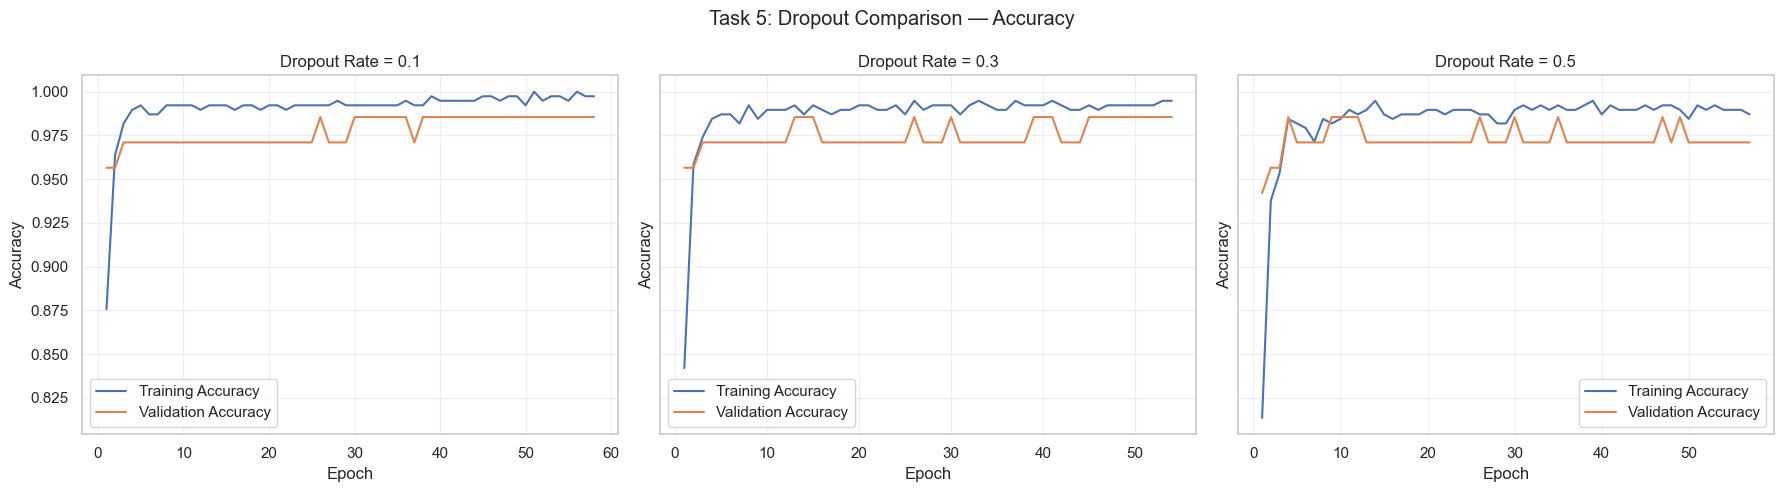

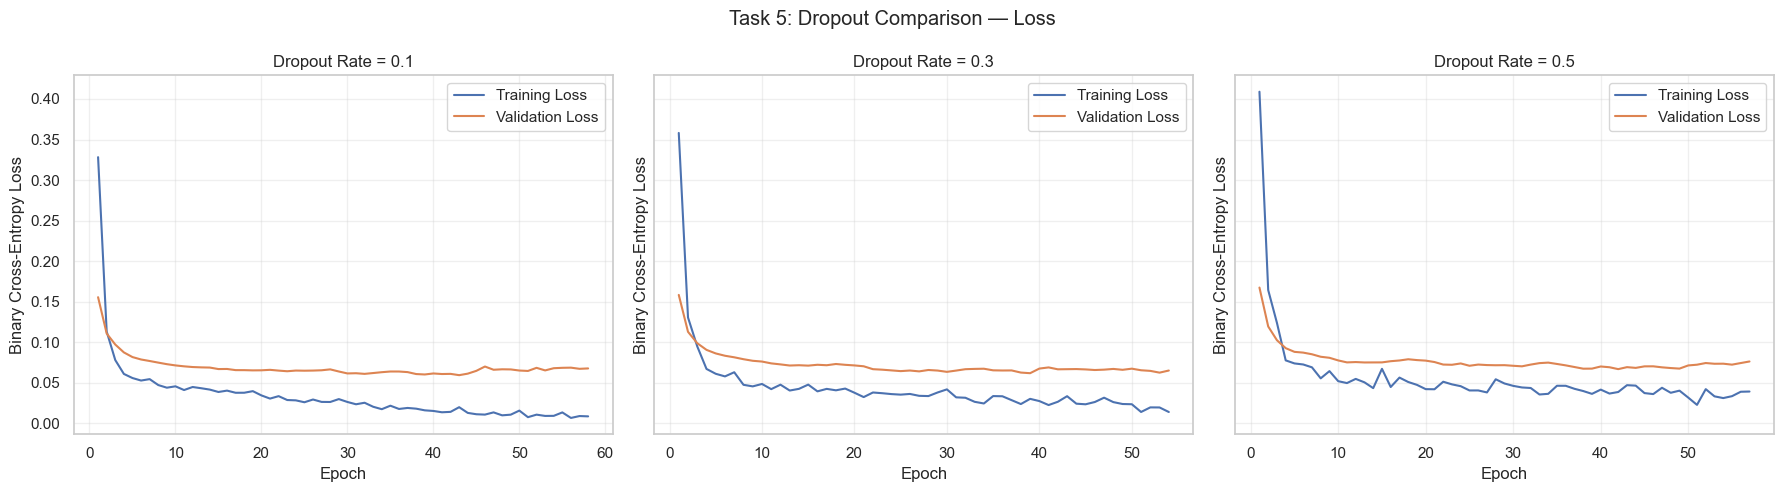


Best Dropout Configuration
--------------------------------------------------
Selected dropout rate : 0.1
Best validation loss  : 0.0594
Best validation accuracy: 0.9855
Selection criterion   : Lowest validation loss

DROPOUT TEST PERFORMANCE COMPARISON


,Dropout Rate,Test Loss,Test Accuracy,Precision (Benign),Recall (Malignant),Recall (Benign),F1-Score (Benign)
0,0.1,0.0894,0.9649,0.9857,0.9762,0.9583,0.9718
1,0.3,0.0873,0.9649,0.9857,0.9762,0.9583,0.9718
2,0.5,0.0867,0.9561,0.9855,0.9762,0.9444,0.9645



Generalization Gap at Best Validation-Loss Epoch
-----------------------------------------------------------------


,Dropout Rate,Training Accuracy at Best Loss,Validation Accuracy at Best Loss,Accuracy Gap at Best Loss
0,0.1,0.9948,0.9855,0.0093
1,0.3,0.9922,0.9855,0.0067
2,0.5,0.9896,0.9710,0.0186



TASK 5 COMPLETED SUCCESSFULLY
Dropout rates evaluated: [0.1, 0.3, 0.5]
Best dropout rate based on validation loss: 0.1
Validation results variable: dropout_results
Test results variable: dropout_test_results
Trained models variable: dropout_models
Training histories variable: dropout_histories
EarlyStopping patience: 15
TASK 5: GENERALIZATION GAP USING RESTORED MODEL WEIGHTS


,Dropout Rate,Training Accuracy,Validation Accuracy,Accuracy Gap,Training Loss,Validation Loss
0,0.1,0.9974,0.9855,0.0119,0.0121,0.0594
1,0.3,0.9922,0.9855,0.0067,0.0226,0.0618
2,0.5,0.9922,0.9710,0.0212,0.0304,0.0669


In [14]:

# ============================================================
# TASK 5: DROPOUT REGULARIZATION
# Dataset: UCI Breast Cancer Wisconsin Diagnostic Dataset
# Dropout rates: 0.1, 0.3, 0.5
# ============================================================

# -------------------- 1. CONFIGURATION -----------------------

SEED = 42
EPOCHS = 100
BATCH_SIZE = 32
LEARNING_RATE = 0.001
PATIENCE = 15

DROPOUT_RATES = [0.1, 0.3, 0.5]

print("=" * 75)
print("TASK 5: DROPOUT REGULARIZATION")
print("=" * 75)

# -------------------- 2. VERIFY DATA -------------------------

required_variables = [
    "X_fit_scaled",
    "y_fit",
    "X_val_scaled",
    "y_val",
    "X_test_scaled",
    "y_test"
]

missing_variables = [
    variable for variable in required_variables
    if variable not in globals()
]

if missing_variables:
    raise NameError(
        f"Missing variables: {missing_variables}. "
        "Run Task 1 successfully before Task 5."
    )

y_fit_array = np.asarray(y_fit).astype(np.int32).ravel()
y_val_array = np.asarray(y_val).astype(np.int32).ravel()
y_test_array = np.asarray(y_test).astype(np.int32).ravel()

print("\nDataset Information")
print("-" * 45)
print(f"Training samples   : {X_fit_scaled.shape[0]}")
print(f"Validation samples : {X_val_scaled.shape[0]}")
print(f"Test samples       : {X_test_scaled.shape[0]}")
print(f"Input features     : {X_fit_scaled.shape[1]}")
print(f"Dropout rates      : {DROPOUT_RATES}")
print(f"EarlyStopping patience: {PATIENCE}")

assert len(X_fit_scaled) == len(y_fit_array)
assert len(X_val_scaled) == len(y_val_array)
assert len(X_test_scaled) == len(y_test_array)

# -------------------- 3. DEFINE MODEL BUILDER ----------------

def build_dropout_mlp(input_features, dropout_rate):
    """
    Architecture:
    Input -> Dense(128, tanh) -> Dropout
          -> Dense(64, tanh) -> Dropout
          -> Dense(1, sigmoid)
    """

    model = keras.Sequential(
        [
            keras.Input(shape=(input_features,)),

            layers.Dense(
                128,
                activation="tanh",
                name="hidden_layer_1"
            ),

            layers.Dropout(
                rate=dropout_rate,
                name="dropout_layer_1"
            ),

            layers.Dense(
                64,
                activation="tanh",
                name="hidden_layer_2"
            ),

            layers.Dropout(
                rate=dropout_rate,
                name="dropout_layer_2"
            ),

            layers.Dense(
                1,
                activation="sigmoid",
                name="output_layer"
            )
        ],
        name=f"MLP_Dropout_{dropout_rate}"
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


# -------------------- 4. TRAIN DROPOUT MODELS ----------------

dropout_models = {}
dropout_histories = {}
dropout_results_list = {}

for dropout_rate in DROPOUT_RATES:

    print("\n" + "=" * 75)
    print(f"TRAINING MLP WITH DROPOUT RATE = {dropout_rate}")
    print("=" * 75)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    model = build_dropout_mlp(
        input_features=X_fit_scaled.shape[1],
        dropout_rate=dropout_rate
    )

    if dropout_rate == DROPOUT_RATES[0]:
        model.summary()

    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=PATIENCE,
        restore_best_weights=True,
        verbose=1
    )

    start_time = time.perf_counter()

    history = model.fit(
        X_fit_scaled,
        y_fit_array,
        validation_data=(X_val_scaled, y_val_array),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stopping],
        shuffle=True,
        verbose=0
    )

    training_time = time.perf_counter() - start_time

    best_epoch = (
        int(np.argmin(history.history["val_loss"])) + 1
    )

    best_val_loss = float(
        np.min(history.history["val_loss"])
    )

    best_val_accuracy_epoch = (
        int(np.argmax(history.history["val_accuracy"])) + 1
    )

    best_val_accuracy = float(
        np.max(history.history["val_accuracy"])
    )

    # Record training and validation accuracy at the best-loss epoch.
    train_accuracy_at_best_loss_epoch = float(
        history.history["accuracy"][best_epoch - 1]
    )

    val_accuracy_at_best_loss_epoch = float(
        history.history["val_accuracy"][best_epoch - 1]
    )

    dropout_models[dropout_rate] = model
    dropout_histories[dropout_rate] = history

    dropout_results_list[dropout_rate] = {
        "Dropout Rate": dropout_rate,
        "Architecture": "30 -> 128 -> 64 -> 1",
        "Epochs Trained": len(history.history["loss"]),
        "Best Loss Epoch": best_epoch,
        "Best Validation Loss": best_val_loss,
        "Best Validation Accuracy": best_val_accuracy,
        "Best Accuracy Epoch": best_val_accuracy_epoch,
        "Training Accuracy at Best Loss": train_accuracy_at_best_loss_epoch,
        "Validation Accuracy at Best Loss": val_accuracy_at_best_loss_epoch,
        "Training Time (seconds)": training_time
    }

    print(f"\nEpochs trained                 : {len(history.history['loss'])}")
    print(f"Best validation-loss epoch     : {best_epoch}")
    print(f"Best validation loss           : {best_val_loss:.4f}")
    print(f"Best validation-accuracy epoch : {best_val_accuracy_epoch}")
    print(f"Best validation accuracy       : {best_val_accuracy:.4f}")
    print(f"Training accuracy at best loss : {train_accuracy_at_best_loss_epoch:.4f}")
    print(f"Validation accuracy at best loss: {val_accuracy_at_best_loss_epoch:.4f}")
    print(f"Training time                  : {training_time:.2f} seconds")


# -------------------- 5. VALIDATION COMPARISON ----------------

dropout_results = pd.DataFrame(
    list(dropout_results_list.values())
)

dropout_results = dropout_results.sort_values(
    by="Best Validation Loss",
    ascending=True
).reset_index(drop=True)

print("\n" + "=" * 110)
print("DROPOUT VALIDATION COMPARISON")
print("=" * 110)

display(dropout_results.round(4))


# -------------------- 6. PLOT ACCURACY CURVES -----------------

fig, axes = plt.subplots(
    1, len(DROPOUT_RATES),
    figsize=(18, 5),
    sharey=True
)

for ax, dropout_rate in zip(axes, DROPOUT_RATES):

    history = dropout_histories[dropout_rate]

    epochs = range(1, len(history.history["accuracy"]) + 1)

    ax.plot(
        epochs,
        history.history["accuracy"],
        label="Training Accuracy"
    )

    ax.plot(
        epochs,
        history.history["val_accuracy"],
        label="Validation Accuracy"
    )

    ax.set_title(f"Dropout Rate = {dropout_rate}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle("Task 5: Dropout Comparison — Accuracy")
plt.tight_layout()
plt.show()


# -------------------- 7. PLOT LOSS CURVES ---------------------

fig, axes = plt.subplots(
    1, len(DROPOUT_RATES),
    figsize=(18, 5),
    sharey=True
)

for ax, dropout_rate in zip(axes, DROPOUT_RATES):

    history = dropout_histories[dropout_rate]

    epochs = range(1, len(history.history["loss"]) + 1)

    ax.plot(
        epochs,
        history.history["loss"],
        label="Training Loss"
    )

    ax.plot(
        epochs,
        history.history["val_loss"],
        label="Validation Loss"
    )

    ax.set_title(f"Dropout Rate = {dropout_rate}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Binary Cross-Entropy Loss")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle("Task 5: Dropout Comparison — Loss")
plt.tight_layout()
plt.show()


# -------------------- 8. SELECT BEST VALIDATION MODEL ----------

best_dropout_rate = float(
    dropout_results.loc[0, "Dropout Rate"]
)

best_dropout_model = dropout_models[best_dropout_rate]

print("\nBest Dropout Configuration")
print("-" * 50)
print(f"Selected dropout rate : {best_dropout_rate}")
print(
    f"Best validation loss  : "
    f"{dropout_results.loc[0, 'Best Validation Loss']:.4f}"
)
print(
    f"Best validation accuracy: "
    f"{dropout_results.loc[0, 'Best Validation Accuracy']:.4f}"
)
print("Selection criterion   : Lowest validation loss")


# -------------------- 9. TEST EVALUATION -----------------------

# Evaluate the configurations on the held-out test set.
# Use validation results for selection, not test metrics.

dropout_test_results_list = []

for dropout_rate in DROPOUT_RATES:

    model = dropout_models[dropout_rate]

    test_loss, test_accuracy = model.evaluate(
        X_test_scaled,
        y_test_array,
        verbose=0
    )

    probabilities = model.predict(
        X_test_scaled,
        verbose=0
    ).ravel()

    predictions = (
        probabilities >= 0.5
    ).astype(np.int32)

    dropout_test_results_list.append(
        {
            "Dropout Rate": dropout_rate,
            "Test Loss": float(test_loss),
            "Test Accuracy": float(test_accuracy),

            "Precision (Benign)": float(
                precision_score(
                    y_test_array,
                    predictions,
                    pos_label=1,
                    zero_division=0
                )
            ),

            "Recall (Malignant)": float(
                recall_score(
                    y_test_array,
                    predictions,
                    pos_label=0,
                    zero_division=0
                )
            ),

            "Recall (Benign)": float(
                recall_score(
                    y_test_array,
                    predictions,
                    pos_label=1,
                    zero_division=0
                )
            ),

            "F1-Score (Benign)": float(
                f1_score(
                    y_test_array,
                    predictions,
                    pos_label=1,
                    zero_division=0
                )
            )
        }
    )

dropout_test_results = pd.DataFrame(
    dropout_test_results_list
)

print("\n" + "=" * 100)
print("DROPOUT TEST PERFORMANCE COMPARISON")
print("=" * 100)

display(dropout_test_results.round(4))


# -------------------- 10. GENERALIZATION GAP ------------------

dropout_results["Accuracy Gap at Best Loss"] = (
    dropout_results["Training Accuracy at Best Loss"]
    - dropout_results["Validation Accuracy at Best Loss"]
)

print("\nGeneralization Gap at Best Validation-Loss Epoch")
print("-" * 65)

display(
    dropout_results[
        [
            "Dropout Rate",
            "Training Accuracy at Best Loss",
            "Validation Accuracy at Best Loss",
            "Accuracy Gap at Best Loss"
        ]
    ].round(4)
)


# -------------------- 11. TASK SUMMARY -------------------------

print("\n" + "=" * 75)
print("TASK 5 COMPLETED SUCCESSFULLY")
print("=" * 75)

print("Dropout rates evaluated:", DROPOUT_RATES)
print("Best dropout rate based on validation loss:", best_dropout_rate)
print("Validation results variable: dropout_results")
print("Test results variable: dropout_test_results")
print("Trained models variable: dropout_models")
print("Training histories variable: dropout_histories")
print("EarlyStopping patience:", PATIENCE)



# ============================================================
# TASK 5: CONSISTENT GENERALIZATION GAP EVALUATION
# ============================================================

generalization_results = []

for rate in DROPOUT_RATES:

    model = dropout_models[rate]

    train_loss, train_acc = model.evaluate(
        X_fit_scaled,
        y_fit_array,
        verbose=0
    )

    val_loss, val_acc = model.evaluate(
        X_val_scaled,
        y_val_array,
        verbose=0
    )

    generalization_results.append({
        "Dropout Rate": rate,
        "Training Accuracy": float(train_acc),
        "Validation Accuracy": float(val_acc),
        "Accuracy Gap": float(train_acc - val_acc),
        "Training Loss": float(train_loss),
        "Validation Loss": float(val_loss)
    })

dropout_generalization_results = pd.DataFrame(
    generalization_results
)

print("=" * 75)
print("TASK 5: GENERALIZATION GAP USING RESTORED MODEL WEIGHTS")
print("=" * 75)

display(dropout_generalization_results.round(4))



TASK 6: L1, L2 AND COMBINED REGULARIZATION

Dataset Information
---------------------------------------------
Training samples     : 386
Validation samples   : 69
Test samples         : 114
Input features       : 30
Regularization types : ['None', 'L1', 'L2', 'L1 + L2']
L1 strength          : 0.001
L2 strength          : 0.001
EarlyStopping patience: 15

TRAINING MODEL: None


Model: "MLP_Regularization"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ hidden_layer_1 (Dense)               │ (None, 128)                 │           3,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ hidden_layer_2 (Dense)               │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output_layer (Dense)                 │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 12,289 (48.00 KB)

 Trainable params: 12,289 (48.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 53: early stopping
Restoring model weights from the end of the best epoch: 38.
Epochs trained              : 53
Best validation-loss epoch  : 38
Best validation loss        : 0.0691
Best validation accuracy    : 0.9710
Best validation-accuracy epoch: 2
Restored training accuracy  : 0.9974
Restored validation accuracy: 0.9710
Training time               : 19.73 seconds

TRAINING MODEL: L1
Restoring model weights from the end of the best epoch: 100.
Epochs trained              : 100
Best validation-loss epoch  : 100
Best validation loss        : 0.1082
Best validation accuracy    : 0.9710
Best validation-accuracy epoch: 2
Restored training accuracy  : 0.9922
Restored validation accuracy: 0.9565
Training time               : 35.25 seconds

TRAINING MODEL: L2
Epoch 93: early stopping
Restoring model weights from the end of the best epoch: 78.
Epochs trained              : 93
Best validation-loss epoch  : 78
Best validation loss        : 0.0993
Best validation accuracy    : 0.9710
Bes

,Regularization,Architecture,L1 Strength,L2 Strength,Epochs Trained,Best Loss Epoch,Best Validation Loss,Best Validation Accuracy,Best Accuracy Epoch,Validation Accuracy at Best-Loss Epoch,Restored Training Accuracy,Restored Validation Accuracy,Training Time (seconds)
0,None,30 -> 128 -> 64 -> 1,0.000,0.000,53,38,0.0691,0.971,2,0.9710,0.9974,0.9710,19.7299
1,L2,30 -> 128 -> 64 -> 1,0.000,0.001,93,78,0.0993,0.971,2,0.9565,1.0000,0.9565,32.6565
2,L1,30 -> 128 -> 64 -> 1,0.001,0.000,100,100,0.1082,0.971,2,0.9565,0.9922,0.9565,35.2508
3,L1 + L2,30 -> 128 -> 64 -> 1,0.001,0.001,100,100,0.1254,0.971,3,0.9710,0.9922,0.9710,35.4531


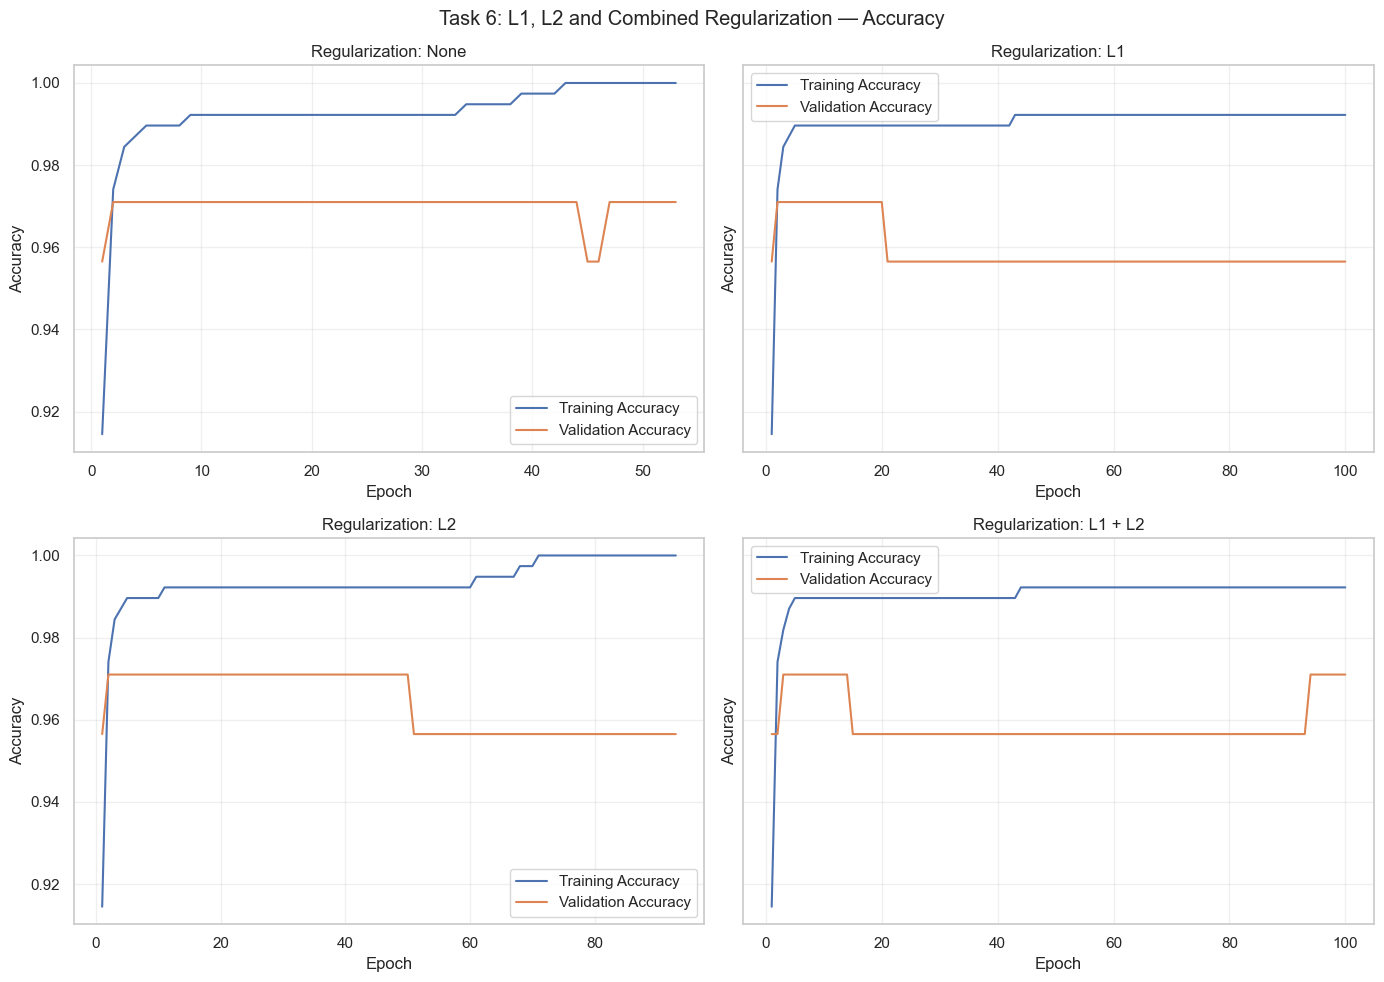

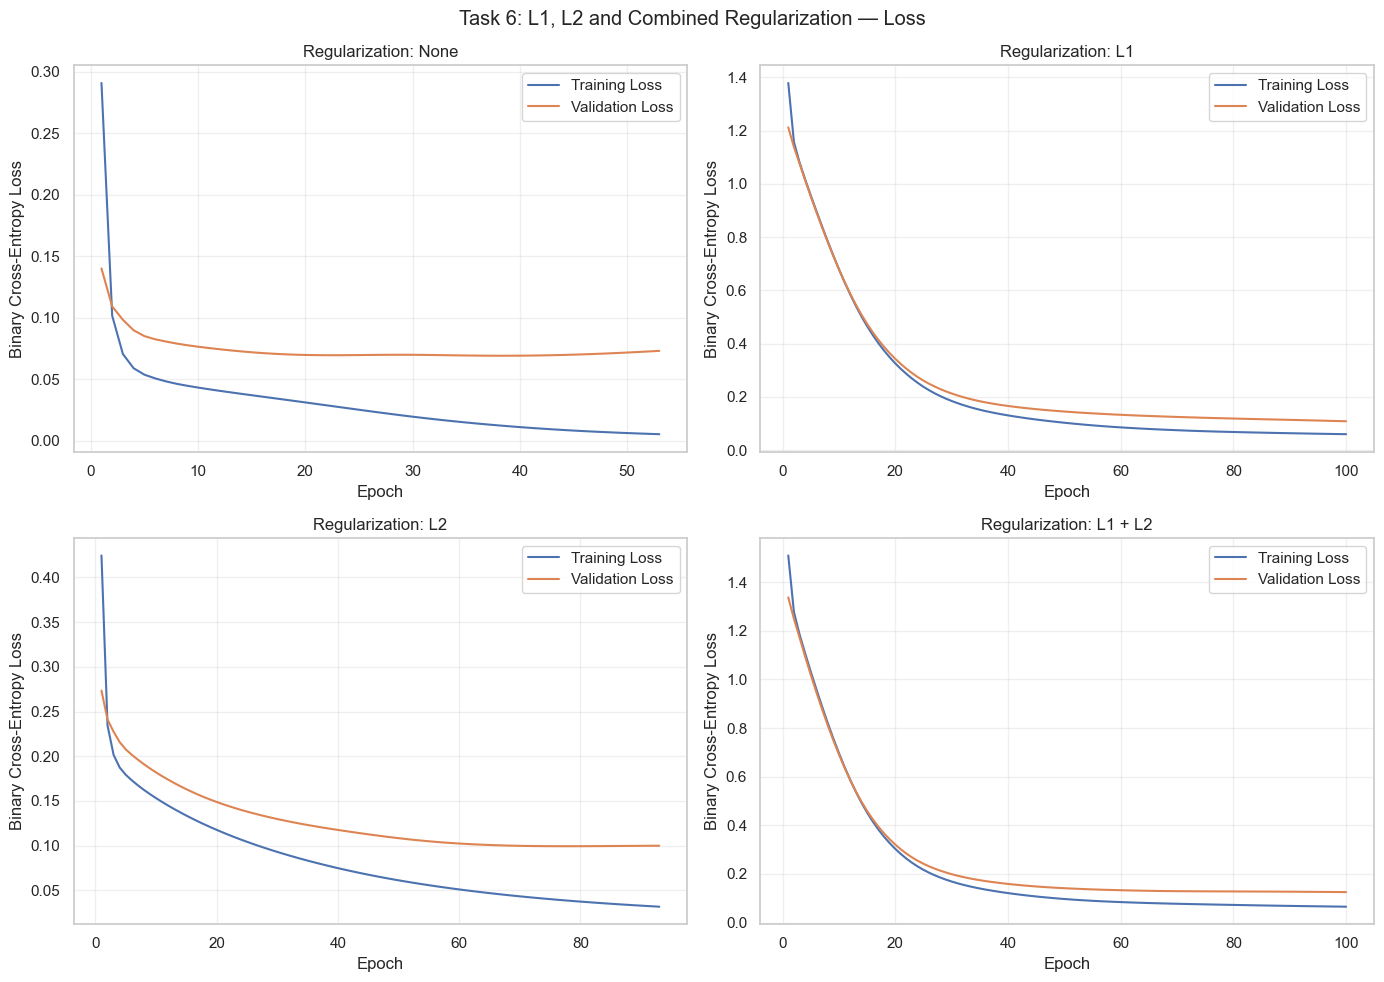


Best Configuration Based on Validation Loss
-------------------------------------------------------
Regularization method : None
Best validation loss  : 0.0691
Restored validation accuracy: 0.9710

REGULARIZATION TEST PERFORMANCE COMPARISON


,Regularization,Test Loss,Test Accuracy,Precision (Benign),Recall (Malignant),Recall (Benign),F1-Score (Benign)
0,None,0.0837,0.9737,0.9859,0.9762,0.9722,0.9790
1,L1,0.1192,0.9561,0.9855,0.9762,0.9444,0.9645
2,L2,0.1066,0.9825,0.9861,0.9762,0.9861,0.9861
3,L1 + L2,0.1138,0.9649,0.9857,0.9762,0.9583,0.9718



Generalization Gap Analysis
------------------------------------------------------------


,Regularization,Restored Training Accuracy,Restored Validation Accuracy,Accuracy Gap,Best Validation Loss
0,None,0.9974,0.9710,0.0264,0.0691
1,L2,1.0000,0.9565,0.0435,0.0993
2,L1,0.9922,0.9565,0.0357,0.1082
3,L1 + L2,0.9922,0.9710,0.0212,0.1254



TASK 6 COMPLETED SUCCESSFULLY
Configurations evaluated: ['None', 'L1', 'L2', 'L1 + L2']
Best validation configuration: None
Validation results: regularization_results
Test results: regularization_test_results
Trained models: regularization_models
Training histories: regularization_histories
EarlyStopping patience: 15


In [15]:

# ============================================================
# TASK 6: L1, L2 AND COMBINED REGULARIZATION
# Dataset: UCI Breast Cancer Wisconsin Diagnostic Dataset
# ============================================================

# -------------------- 1. CONFIGURATION -----------------------

SEED = 42
EPOCHS = 100
BATCH_SIZE = 32
LEARNING_RATE = 0.001
PATIENCE = 15

L1_STRENGTH = 0.001
L2_STRENGTH = 0.001

REGULARIZATION_CONFIGS = {
    "None": {"l1": 0.0, "l2": 0.0},
    "L1": {"l1": L1_STRENGTH, "l2": 0.0},
    "L2": {"l1": 0.0, "l2": L2_STRENGTH},
    "L1 + L2": {
        "l1": L1_STRENGTH,
        "l2": L2_STRENGTH
    }
}

print("=" * 75)
print("TASK 6: L1, L2 AND COMBINED REGULARIZATION")
print("=" * 75)

# -------------------- 2. VERIFY DATA -------------------------

required_variables = [
    "X_fit_scaled",
    "y_fit",
    "X_val_scaled",
    "y_val",
    "X_test_scaled",
    "y_test"
]

missing_variables = [
    variable for variable in required_variables
    if variable not in globals()
]

if missing_variables:
    raise NameError(
        f"Missing variables: {missing_variables}. "
        "Run Task 1 successfully before Task 6."
    )

y_fit_array = np.asarray(y_fit).astype(np.int32).ravel()
y_val_array = np.asarray(y_val).astype(np.int32).ravel()
y_test_array = np.asarray(y_test).astype(np.int32).ravel()

assert len(X_fit_scaled) == len(y_fit_array)
assert len(X_val_scaled) == len(y_val_array)
assert len(X_test_scaled) == len(y_test_array)

assert X_fit_scaled.shape[1] == X_val_scaled.shape[1]
assert X_fit_scaled.shape[1] == X_test_scaled.shape[1]

print("\nDataset Information")
print("-" * 45)
print(f"Training samples     : {X_fit_scaled.shape[0]}")
print(f"Validation samples   : {X_val_scaled.shape[0]}")
print(f"Test samples         : {X_test_scaled.shape[0]}")
print(f"Input features       : {X_fit_scaled.shape[1]}")
print(f"Regularization types : {list(REGULARIZATION_CONFIGS.keys())}")
print(f"L1 strength          : {L1_STRENGTH}")
print(f"L2 strength          : {L2_STRENGTH}")
print(f"EarlyStopping patience: {PATIENCE}")

# -------------------- 3. DEFINE MODEL BUILDER ----------------

def build_regularized_mlp(
    input_features,
    l1_strength,
    l2_strength
):
    """
    Architecture:
    Input -> Dense(128, tanh)
          -> Dense(64, tanh)
          -> Dense(1, sigmoid)

    Regularization is applied to hidden-layer kernel weights.
    """

    if l1_strength > 0 and l2_strength > 0:
        regularizer = keras.regularizers.L1L2(
            l1=l1_strength,
            l2=l2_strength
        )

    elif l1_strength > 0:
        regularizer = keras.regularizers.L1(
            l1=l1_strength
        )

    elif l2_strength > 0:
        regularizer = keras.regularizers.L2(
            l2=l2_strength
        )

    else:
        regularizer = None

    model = keras.Sequential(
        [
            keras.Input(shape=(input_features,)),

            layers.Dense(
                128,
                activation="tanh",
                kernel_regularizer=regularizer,
                name="hidden_layer_1"
            ),

            layers.Dense(
                64,
                activation="tanh",
                kernel_regularizer=regularizer,
                name="hidden_layer_2"
            ),

            layers.Dense(
                1,
                activation="sigmoid",
                name="output_layer"
            )
        ],
        name="MLP_Regularization"
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


# -------------------- 4. TRAIN REGULARIZATION MODELS ----------

regularization_models = {}
regularization_histories = {}
regularization_results_list = []

for config_name, config in REGULARIZATION_CONFIGS.items():

    print("\n" + "=" * 75)
    print(f"TRAINING MODEL: {config_name}")
    print("=" * 75)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    model = build_regularized_mlp(
        input_features=X_fit_scaled.shape[1],
        l1_strength=config["l1"],
        l2_strength=config["l2"]
    )

    if config_name == "None":
        model.summary()

    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=PATIENCE,
        restore_best_weights=True,
        verbose=1
    )

    start_time = time.perf_counter()

    history = model.fit(
        X_fit_scaled,
        y_fit_array,
        validation_data=(X_val_scaled, y_val_array),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stopping],
        shuffle=True,
        verbose=0
    )

    training_time = time.perf_counter() - start_time

    best_epoch = (
        int(np.argmin(history.history["val_loss"])) + 1
    )

    best_val_loss = float(
        np.min(history.history["val_loss"])
    )

    best_val_accuracy_epoch = (
        int(np.argmax(history.history["val_accuracy"])) + 1
    )

    best_val_accuracy = float(
        np.max(history.history["val_accuracy"])
    )

    val_accuracy_at_best_loss = float(
        history.history["val_accuracy"][best_epoch - 1]
    )

    epochs_trained = len(history.history["loss"])

    # Evaluate restored model weights in inference mode.
    train_loss, train_accuracy = model.evaluate(
        X_fit_scaled,
        y_fit_array,
        verbose=0
    )

    val_loss, val_accuracy = model.evaluate(
        X_val_scaled,
        y_val_array,
        verbose=0
    )

    regularization_models[config_name] = model
    regularization_histories[config_name] = history

    regularization_results_list.append(
        {
            "Regularization": config_name,
            "Architecture": "30 -> 128 -> 64 -> 1",
            "L1 Strength": config["l1"],
            "L2 Strength": config["l2"],
            "Epochs Trained": epochs_trained,
            "Best Loss Epoch": best_epoch,
            "Best Validation Loss": best_val_loss,
            "Best Validation Accuracy": best_val_accuracy,
            "Best Accuracy Epoch": best_val_accuracy_epoch,
            "Validation Accuracy at Best-Loss Epoch":
                val_accuracy_at_best_loss,
            "Restored Training Accuracy": float(train_accuracy),
            "Restored Validation Accuracy": float(val_accuracy),
            "Training Time (seconds)": training_time
        }
    )

    print(f"Epochs trained              : {epochs_trained}")
    print(f"Best validation-loss epoch  : {best_epoch}")
    print(f"Best validation loss        : {best_val_loss:.4f}")
    print(f"Best validation accuracy    : {best_val_accuracy:.4f}")
    print(f"Best validation-accuracy epoch: {best_val_accuracy_epoch}")
    print(f"Restored training accuracy  : {train_accuracy:.4f}")
    print(f"Restored validation accuracy: {val_accuracy:.4f}")
    print(f"Training time               : {training_time:.2f} seconds")


# -------------------- 5. VALIDATION RESULTS COMPARISON --------

regularization_results = pd.DataFrame(
    regularization_results_list
)

regularization_results = regularization_results.sort_values(
    by="Best Validation Loss",
    ascending=True
).reset_index(drop=True)

print("\n" + "=" * 120)
print("REGULARIZATION VALIDATION COMPARISON")
print("=" * 120)

display(regularization_results.round(4))


# -------------------- 6. PLOT ACCURACY CURVES -----------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10),
    sharey=True
)

for ax, config_name in zip(
    axes.flatten(),
    REGULARIZATION_CONFIGS.keys()
):

    history = regularization_histories[config_name]

    epochs = range(1, len(history.history["accuracy"]) + 1)

    ax.plot(
        epochs,
        history.history["accuracy"],
        label="Training Accuracy"
    )

    ax.plot(
        epochs,
        history.history["val_accuracy"],
        label="Validation Accuracy"
    )

    ax.set_title(f"Regularization: {config_name}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle("Task 6: L1, L2 and Combined Regularization — Accuracy")
plt.tight_layout()
plt.show()


# -------------------- 7. PLOT LOSS CURVES ---------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10),
    sharey=False
)

for ax, config_name in zip(
    axes.flatten(),
    REGULARIZATION_CONFIGS.keys()
):

    history = regularization_histories[config_name]

    epochs = range(1, len(history.history["loss"]) + 1)

    ax.plot(
        epochs,
        history.history["loss"],
        label="Training Loss"
    )

    ax.plot(
        epochs,
        history.history["val_loss"],
        label="Validation Loss"
    )

    ax.set_title(f"Regularization: {config_name}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Binary Cross-Entropy Loss")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle("Task 6: L1, L2 and Combined Regularization — Loss")
plt.tight_layout()
plt.show()


# -------------------- 8. SELECT BEST VALIDATION MODEL ----------

best_regularization = regularization_results.loc[
    0, "Regularization"
]

best_regularized_model = regularization_models[
    best_regularization
]

print("\nBest Configuration Based on Validation Loss")
print("-" * 55)
print(f"Regularization method : {best_regularization}")
print(
    f"Best validation loss  : "
    f"{regularization_results.loc[0, 'Best Validation Loss']:.4f}"
)
print(
    f"Restored validation accuracy: "
    f"{regularization_results.loc[0, 'Restored Validation Accuracy']:.4f}"
)


# -------------------- 9. TEST EVALUATION -----------------------

# Test metrics are for reporting only.
# Do not use them to tune or select the configuration.

regularization_test_results_list = []

for config_name in REGULARIZATION_CONFIGS:

    model = regularization_models[config_name]

    test_loss, test_accuracy = model.evaluate(
        X_test_scaled,
        y_test_array,
        verbose=0
    )

    probabilities = model.predict(
        X_test_scaled,
        verbose=0
    ).ravel()

    predictions = (
        probabilities >= 0.5
    ).astype(np.int32)

    regularization_test_results_list.append(
        {
            "Regularization": config_name,
            "Test Loss": float(test_loss),
            "Test Accuracy": float(test_accuracy),

            "Precision (Benign)": float(
                precision_score(
                    y_test_array,
                    predictions,
                    pos_label=1,
                    zero_division=0
                )
            ),

            "Recall (Malignant)": float(
                recall_score(
                    y_test_array,
                    predictions,
                    pos_label=0,
                    zero_division=0
                )
            ),

            "Recall (Benign)": float(
                recall_score(
                    y_test_array,
                    predictions,
                    pos_label=1,
                    zero_division=0
                )
            ),

            "F1-Score (Benign)": float(
                f1_score(
                    y_test_array,
                    predictions,
                    pos_label=1,
                    zero_division=0
                )
            )
        }
    )

regularization_test_results = pd.DataFrame(
    regularization_test_results_list
)

print("\n" + "=" * 100)
print("REGULARIZATION TEST PERFORMANCE COMPARISON")
print("=" * 100)

display(regularization_test_results.round(4))


# -------------------- 10. GENERALIZATION GAP ------------------

regularization_results["Accuracy Gap"] = (
    regularization_results["Restored Training Accuracy"]
    - regularization_results["Restored Validation Accuracy"]
)

print("\nGeneralization Gap Analysis")
print("-" * 60)

display(
    regularization_results[
        [
            "Regularization",
            "Restored Training Accuracy",
            "Restored Validation Accuracy",
            "Accuracy Gap",
            "Best Validation Loss"
        ]
    ].round(4)
)


# -------------------- 11. TASK SUMMARY -------------------------

print("\n" + "=" * 75)
print("TASK 6 COMPLETED SUCCESSFULLY")
print("=" * 75)

print("Configurations evaluated:", list(REGULARIZATION_CONFIGS.keys()))
print("Best validation configuration:", best_regularization)
print("Validation results: regularization_results")
print("Test results: regularization_test_results")
print("Trained models: regularization_models")
print("Training histories: regularization_histories")
print("EarlyStopping patience:", PATIENCE)



In [16]:
# ============================================================
# TASK 7: FINAL COMPARISON, BUSINESS INSIGHTS & NOTEBOOK QUALITY
# ============================================================

print("=" * 80)
print("TASK 7: FINAL COMPARISON, BUSINESS INSIGHTS & NOTEBOOK QUALITY")
print("=" * 80)


# ------------------------------------------------------------
# TASK 7.1: FINAL COMPARISON OF ALL MODELS
# ------------------------------------------------------------

print("\nTASK 7.1: FINAL COMPARISON OF ALL MODELS")
print("-" * 80)

# Results recorded from Tasks 2-6.
# Do not invent metrics that were not recorded.
# Test metrics are for final evaluation, not model selection.

final_comparison_data = [
    {
        "Model": "SLP Baseline",
        "Validation Accuracy": float("nan"),
        "Validation Loss": float("nan"),
        "Test Accuracy": 0.9561,
        "Test Loss": 0.1725,
        "Malignant Recall": 0.9286,
        "Benign Recall": 0.9722,
        "Benign Precision": 0.9589,
        "Benign F1-Score": 0.9655
    },
    {
        "Model": "MLP - ReLU",
        "Validation Accuracy": 0.9710,
        "Validation Loss": 0.1009,
        "Test Accuracy": float("nan"),
        "Test Loss": float("nan"),
        "Malignant Recall": float("nan"),
        "Benign Recall": float("nan"),
        "Benign Precision": float("nan"),
        "Benign F1-Score": float("nan")
    },
    {
        "Model": "MLP - Tanh",
        "Validation Accuracy": 0.9855,
        "Validation Loss": 0.0724,
        "Test Accuracy": 0.9737,
        "Test Loss": 0.0894,
        "Malignant Recall": 0.9762,
        "Benign Recall": 0.9722,
        "Benign Precision": 0.9859,
        "Benign F1-Score": 0.9790
    },
    {
        "Model": "MLP - Sigmoid Hidden Layers",
        "Validation Accuracy": 0.9710,
        "Validation Loss": 0.0903,
        "Test Accuracy": float("nan"),
        "Test Loss": float("nan"),
        "Malignant Recall": float("nan"),
        "Benign Recall": float("nan"),
        "Benign Precision": float("nan"),
        "Benign F1-Score": float("nan")
    },
    {
        "Model": "MLP - Early Stopping",
        "Validation Accuracy": 0.9710,
        "Validation Loss": 0.0691,
        "Test Accuracy": 0.9737,
        "Test Loss": 0.0837,
        "Malignant Recall": 0.9762,
        "Benign Recall": 0.9722,
        "Benign Precision": 0.9859,
        "Benign F1-Score": 0.9790
    },
    {
        "Model": "MLP - Dropout 0.1",
        "Validation Accuracy": 0.9855,
        "Validation Loss": 0.0594,
        "Test Accuracy": 0.9649,
        "Test Loss": 0.0894,
        "Malignant Recall": 0.9762,
        "Benign Recall": 0.9583,
        "Benign Precision": 0.9857,
        "Benign F1-Score": 0.9718
    },
    {
        "Model": "MLP - Dropout 0.3",
        "Validation Accuracy": 0.9855,
        "Validation Loss": 0.0618,
        "Test Accuracy": 0.9649,
        "Test Loss": 0.0873,
        "Malignant Recall": 0.9762,
        "Benign Recall": 0.9583,
        "Benign Precision": 0.9857,
        "Benign F1-Score": 0.9718
    },
    {
        "Model": "MLP - Dropout 0.5",
        "Validation Accuracy": 0.9710,
        "Validation Loss": 0.0669,
        "Test Accuracy": 0.9561,
        "Test Loss": 0.0867,
        "Malignant Recall": 0.9762,
        "Benign Recall": 0.9444,
        "Benign Precision": 0.9855,
        "Benign F1-Score": 0.9645
    },
    {
        "Model": "MLP - No Regularization",
        "Validation Accuracy": 0.9710,
        "Validation Loss": 0.0691,
        "Test Accuracy": 0.9737,
        "Test Loss": 0.0837,
        "Malignant Recall": 0.9762,
        "Benign Recall": 0.9722,
        "Benign Precision": 0.9859,
        "Benign F1-Score": 0.9790
    },
    {
        "Model": "MLP - L1 Regularization",
        "Validation Accuracy": 0.9565,
        "Validation Loss": 0.1082,
        "Test Accuracy": 0.9561,
        "Test Loss": 0.1192,
        "Malignant Recall": 0.9762,
        "Benign Recall": 0.9444,
        "Benign Precision": 0.9855,
        "Benign F1-Score": 0.9645
    },
    {
        "Model": "MLP - L2 Regularization",
        "Validation Accuracy": 0.9565,
        "Validation Loss": 0.0993,
        "Test Accuracy": 0.9825,
        "Test Loss": 0.1066,
        "Malignant Recall": 0.9762,
        "Benign Recall": 0.9861,
        "Benign Precision": 0.9861,
        "Benign F1-Score": 0.9861
    },
    {
        "Model": "MLP - L1 + L2 Regularization",
        "Validation Accuracy": 0.9710,
        "Validation Loss": 0.1254,
        "Test Accuracy": 0.9649,
        "Test Loss": 0.1138,
        "Malignant Recall": 0.9762,
        "Benign Recall": 0.9583,
        "Benign Precision": 0.9857,
        "Benign F1-Score": 0.9718
    }
]

final_comparison_df = pd.DataFrame(final_comparison_data)

print("\nFinal Model Performance Comparison:")

display(
    final_comparison_df.style.format(
        {
            "Validation Accuracy": "{:.2%}",
            "Validation Loss": "{:.4f}",
            "Test Accuracy": "{:.2%}",
            "Test Loss": "{:.4f}",
            "Malignant Recall": "{:.2%}",
            "Benign Recall": "{:.2%}",
            "Benign Precision": "{:.2%}",
            "Benign F1-Score": "{:.4f}"
        },
        na_rep="N/A"
    )
)


# ------------------------------------------------------------
# COMPARISON SUMMARY
# ------------------------------------------------------------

print("\nComparison Summary")
print("-" * 80)

print("1. SLP Baseline: Test accuracy of 95.61%.")
print("2. Tanh MLP: Validation accuracy of 98.55%.")
print("3. Early Stopping: Restored the best validation-loss weights.")
print("4. Dropout: Performance varied with the dropout rate.")
print("5. L1 Regularization: Test accuracy of 95.61%.")
print("6. L2 Regularization: Highest recorded test accuracy of 98.25%.")
print("7. Combined L1 + L2: Test accuracy of 96.49%.")


# ------------------------------------------------------------
# TASK 7.2: SELECT PROMISING MODELS USING VALIDATION RESULTS
# ------------------------------------------------------------

print("\n\nTASK 7.2: MODEL SELECTION USING VALIDATION RESULTS")
print("-" * 80)

# Validation accuracy is used to shortlist candidate models.
# The test set is not used for selection.

models_with_validation = final_comparison_df.dropna(
    subset=["Validation Accuracy"]
).copy()

highest_validation_accuracy = models_with_validation[
    "Validation Accuracy"
].max()

best_validation_models = models_with_validation[
    models_with_validation["Validation Accuracy"]
    == highest_validation_accuracy
]

print(
    f"Highest recorded validation accuracy: "
    f"{highest_validation_accuracy:.2%}"
)

print("\nModels achieving the highest validation accuracy:")

display(
    best_validation_models[
        ["Model", "Validation Accuracy", "Validation Loss"]
    ].reset_index(drop=True)
)

print(
    "\nInterpretation: Multiple models share the highest recorded "
    "validation accuracy. Their validation losses, architectures, "
    "and experimental settings should be considered before selecting "
    "a final model."
)

print(
    "The Tanh MLP and the dropout models with rates 0.1 and 0.3 "
    "achieved 98.55% validation accuracy in the recorded experiments."
)

print(
    "The no-regularization and early-stopping results must be interpreted "
    "according to their own recorded validation metrics."
)


# ------------------------------------------------------------
# TASK 7.3: BUSINESS INSIGHTS
# ------------------------------------------------------------

print("\n\nTASK 7.3: BUSINESS INSIGHTS")
print("-" * 80)

print("""
1. Potential practical value:
   A classification model may help healthcare professionals prioritize
   cases for further examination. It must not replace professional
   diagnosis or clinical judgment.

2. Importance of malignant recall:
   Malignant recall measures the proportion of actual malignant cases
   correctly identified. Missing a malignant case can have serious
   consequences, so this metric deserves particular attention.

3. Tanh MLP performance:
   The recorded Tanh MLP achieved 97.37% test accuracy and 97.62%
   malignant recall. On a test set containing 42 malignant cases,
   this corresponds to correctly identifying 41 cases.

4. L2 regularization:
   The L2 model achieved the highest recorded test accuracy of 98.25%.
   However, test performance alone must not be used to select the final
   model.

5. Training efficiency:
   Early stopping can reduce unnecessary training by stopping when
   validation loss no longer improves and restoring the best weights.

6. Responsible use:
   Real-world medical use would require independent clinical validation,
   privacy safeguards, and evaluation on representative patient groups.
""")


# ------------------------------------------------------------
# TASK 7.4: LIMITATIONS AND FUTURE IMPROVEMENTS
# ------------------------------------------------------------

print("\n\nTASK 7.4: LIMITATIONS AND FUTURE IMPROVEMENTS")
print("-" * 80)

limitations_and_improvements = [
    {
        "Limitation": "Small dataset",
        "Future Improvement": (
            "Evaluate using larger and more diverse datasets."
        )
    },
    {
        "Limitation": "Limited test samples",
        "Future Improvement": (
            "Use repeated stratified cross-validation and independent evaluation."
        )
    },
    {
        "Limitation": "Potential dataset bias",
        "Future Improvement": (
            "Validate performance across relevant patient populations."
        )
    },
    {
        "Limitation": "False negative predictions",
        "Future Improvement": (
            "Study malignant recall, confusion matrices, and decision thresholds."
        )
    },
    {
        "Limitation": "Incomplete recorded metrics",
        "Future Improvement": (
            "Evaluate missing model results using the same test set and metrics."
        )
    },
    {
        "Limitation": "No clinical validation",
        "Future Improvement": (
            "Conduct appropriate clinical evaluation before practical deployment."
        )
    }
]

limitations_df = pd.DataFrame(limitations_and_improvements)

print("\nLimitations and Future Improvements:")

display(limitations_df)

print(
    "\nImportant: High accuracy on this dataset does not establish that "
    "the model is suitable for real-world medical diagnosis."
)


# ------------------------------------------------------------
# TASK 7.5: NOTEBOOK QUALITY CHECKS
# ------------------------------------------------------------

print("\n\nTASK 7.5: NOTEBOOK QUALITY CHECKS")
print("-" * 80)

required_variables = [
    "X_fit_scaled",
    "y_fit",
    "X_val_scaled",
    "y_val",
    "X_test_scaled",
    "y_test",
    "final_comparison_df"
]

missing_variables = [
    variable_name
    for variable_name in required_variables
    if variable_name not in globals()
]

if not missing_variables:
    print("PASS: Required dataset and comparison variables are available.")
else:
    print("WARNING: Missing variables:", missing_variables)


# Check dataset dimensions and feature-label lengths.

if all(
    variable_name in globals()
    for variable_name in [
        "X_fit_scaled",
        "y_fit",
        "X_val_scaled",
        "y_val",
        "X_test_scaled",
        "y_test"
    ]
):
    print("\nDataset Split Dimensions")
    print("Training set:", X_fit_scaled.shape)
    print("Validation set:", X_val_scaled.shape)
    print("Test set:", X_test_scaled.shape)

    assert len(X_fit_scaled) == len(y_fit), (
        "Training features and labels have different lengths."
    )

    assert len(X_val_scaled) == len(y_val), (
        "Validation features and labels have different lengths."
    )

    assert len(X_test_scaled) == len(y_test), (
        "Test features and labels have different lengths."
    )

    print("PASS: Feature and label lengths match.")


# Check the comparison table.

assert not final_comparison_df.empty, (
    "The final comparison table is empty."
)

assert final_comparison_df["Model"].is_unique, (
    "Duplicate model names were found."
)

print("\nPASS: Comparison table is not empty.")
print("PASS: Model names are unique.")

print("Models included:", len(final_comparison_df))

print(
    "Models missing recorded test accuracy:",
    final_comparison_df["Test Accuracy"].isna().sum()
)


# Check recorded metric ranges.

metric_columns = [
    "Validation Accuracy",
    "Test Accuracy",
    "Malignant Recall",
    "Benign Recall",
    "Benign Precision",
    "Benign F1-Score"
]

for column_name in metric_columns:
    valid_values = final_comparison_df[column_name].dropna()

    assert valid_values.between(0, 1).all(), (
        f"Invalid metric values found in {column_name}."
    )

print("PASS: Recorded classification metrics are within [0, 1].")


# Check test and validation losses are nonnegative where available.

loss_columns = [
    "Validation Loss",
    "Test Loss"
]

for column_name in loss_columns:
    valid_values = final_comparison_df[column_name].dropna()

    assert (valid_values >= 0).all(), (
        f"Negative loss values found in {column_name}."
    )

print("PASS: Recorded loss values are nonnegative.")


# ------------------------------------------------------------
# FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("TASK 7 COMPLETED SUCCESSFULLY")
print("=" * 80)

print("""
Final Summary:
- Compared recorded results from Tasks 2-6.
- Kept validation and test metrics separate.
- Identified models with the highest recorded validation accuracy.
- Discussed potential practical value and responsible use.
- Documented limitations and future improvements.
- Checked dataset dimensions and feature-label consistency.
- Checked comparison-table integrity and recorded metric ranges.

Note:
N/A indicates that a metric was not available in the recorded results.
Missing values should not be interpreted as zero performance.
""")

TASK 7: FINAL COMPARISON, BUSINESS INSIGHTS & NOTEBOOK QUALITY

TASK 7.1: FINAL COMPARISON OF ALL MODELS
--------------------------------------------------------------------------------

Final Model Performance Comparison:


,Model,Validation Accuracy,Validation Loss,Test Accuracy,Test Loss,Malignant Recall,Benign Recall,Benign Precision,Benign F1-Score
0,SLP Baseline,N/A,N/A,95.61%,0.1725,92.86%,97.22%,95.89%,0.9655
1,MLP - ReLU,97.10%,0.1009,N/A,N/A,N/A,N/A,N/A,N/A
2,MLP - Tanh,98.55%,0.0724,97.37%,0.0894,97.62%,97.22%,98.59%,0.9790
3,MLP - Sigmoid Hidden Layers,97.10%,0.0903,N/A,N/A,N/A,N/A,N/A,N/A
4,MLP - Early Stopping,97.10%,0.0691,97.37%,0.0837,97.62%,97.22%,98.59%,0.9790
5,MLP - Dropout 0.1,98.55%,0.0594,96.49%,0.0894,97.62%,95.83%,98.57%,0.9718
6,MLP - Dropout 0.3,98.55%,0.0618,96.49%,0.0873,97.62%,95.83%,98.57%,0.9718
7,MLP - Dropout 0.5,97.10%,0.0669,95.61%,0.0867,97.62%,94.44%,98.55%,0.9645
8,MLP - No Regularization,97.10%,0.0691,97.37%,0.0837,97.62%,97.22%,98.59%,0.9790
9,MLP - L1 Regularization,95.65%,0.1082,95.61%,0.1192,97.62%,94.44%,98.55%,0.9645



Comparison Summary
--------------------------------------------------------------------------------
1. SLP Baseline: Test accuracy of 95.61%.
2. Tanh MLP: Validation accuracy of 98.55%.
3. Early Stopping: Restored the best validation-loss weights.
4. Dropout: Performance varied with the dropout rate.
5. L1 Regularization: Test accuracy of 95.61%.
6. L2 Regularization: Highest recorded test accuracy of 98.25%.
7. Combined L1 + L2: Test accuracy of 96.49%.


TASK 7.2: MODEL SELECTION USING VALIDATION RESULTS
--------------------------------------------------------------------------------
Highest recorded validation accuracy: 98.55%

Models achieving the highest validation accuracy:


,Model,Validation Accuracy,Validation Loss
0,MLP - Tanh,0.9855,0.0724
1,MLP - Dropout 0.1,0.9855,0.0594
2,MLP - Dropout 0.3,0.9855,0.0618



Interpretation: Multiple models share the highest recorded validation accuracy. Their validation losses, architectures, and experimental settings should be considered before selecting a final model.
The Tanh MLP and the dropout models with rates 0.1 and 0.3 achieved 98.55% validation accuracy in the recorded experiments.
The no-regularization and early-stopping results must be interpreted according to their own recorded validation metrics.


TASK 7.3: BUSINESS INSIGHTS
--------------------------------------------------------------------------------

1. Potential practical value:
   A classification model may help healthcare professionals prioritize
   cases for further examination. It must not replace professional
   diagnosis or clinical judgment.

2. Importance of malignant recall:
   Malignant recall measures the proportion of actual malignant cases
   correctly identified. Missing a malignant case can have serious
   consequences, so this metric deserves particular attention.

3. 

,Limitation,Future Improvement
0,Small dataset,Evaluate using larger and more diverse datasets.
1,Limited test samples,Use repeated stratified cross-validation and i...
2,Potential dataset bias,Validate performance across relevant patient p...
3,False negative predictions,"Study malignant recall, confusion matrices, an..."
4,Incomplete recorded metrics,Evaluate missing model results using the same ...
5,No clinical validation,Conduct appropriate clinical evaluation before...



Important: High accuracy on this dataset does not establish that the model is suitable for real-world medical diagnosis.


TASK 7.5: NOTEBOOK QUALITY CHECKS
--------------------------------------------------------------------------------
PASS: Required dataset and comparison variables are available.

Dataset Split Dimensions
Training set: (386, 30)
Validation set: (69, 30)
Test set: (114, 30)
PASS: Feature and label lengths match.

PASS: Comparison table is not empty.
PASS: Model names are unique.
Models included: 12
Models missing recorded test accuracy: 2
PASS: Recorded classification metrics are within [0, 1].
PASS: Recorded loss values are nonnegative.

TASK 7 COMPLETED SUCCESSFULLY

Final Summary:
- Compared recorded results from Tasks 2-6.
- Kept validation and test metrics separate.
- Identified models with the highest recorded validation accuracy.
- Discussed potential practical value and responsible use.
- Documented limitations and future improvements.
- Checked dataset dime